In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("EduGuard AI environment ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

EduGuard AI environment ready!
Pandas: 2.3.3
NumPy: 1.26.4


In [2]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\User\Desktop\EduGuard_AI\data\raw")

print(DATA_DIR.exists())

True


In [3]:
for file in sorted(DATA_DIR.glob("*.csv")):
    print(file.name)

assessments.csv
courses.csv
studentAssessment.csv
studentInfo.csv
studentRegistration.csv
studentVle.csv
vle.csv


In [4]:
# Load the smaller datasets first

student_info = pd.read_csv(DATA_DIR / "studentInfo.csv")
student_registration = pd.read_csv(DATA_DIR / "studentRegistration.csv")
student_assessment = pd.read_csv(DATA_DIR / "studentAssessment.csv")
assessments = pd.read_csv(DATA_DIR / "assessments.csv")
courses = pd.read_csv(DATA_DIR / "courses.csv")
vle = pd.read_csv(DATA_DIR / "vle.csv")

print("All smaller datasets loaded successfully!")

All smaller datasets loaded successfully!


In [5]:
datasets = {
    "Student Info": student_info,
    "Student Registration": student_registration,
    "Student Assessment": student_assessment,
    "Assessments": assessments,
    "Courses": courses,
    "VLE": vle
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Student Info: (32593, 12)
Student Registration: (32593, 5)
Student Assessment: (173912, 5)
Assessments: (206, 6)
Courses: (22, 3)
VLE: (6364, 6)


In [6]:
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [7]:
print("Student assessment rows:", len(student_assessment))

print("\nColumn names:")
print(student_assessment.columns.tolist())

print("\nFirst five records:")
display(student_assessment.head())

Student assessment rows: 173912

Column names:
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

First five records:


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78
1,1752,28400,22,0,70
2,1752,31604,17,0,72
3,1752,32885,26,0,69
4,1752,38053,19,0,79


In [8]:
student_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              32593 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB


In [9]:
student_info.isnull().sum()

code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
dtype: int64

In [10]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [11]:
student_info["final_result"].value_counts(normalize=True) * 100

final_result
Pass           37.925321
Withdrawn      31.160065
Fail           21.636548
Distinction     9.278066
Name: proportion, dtype: float64

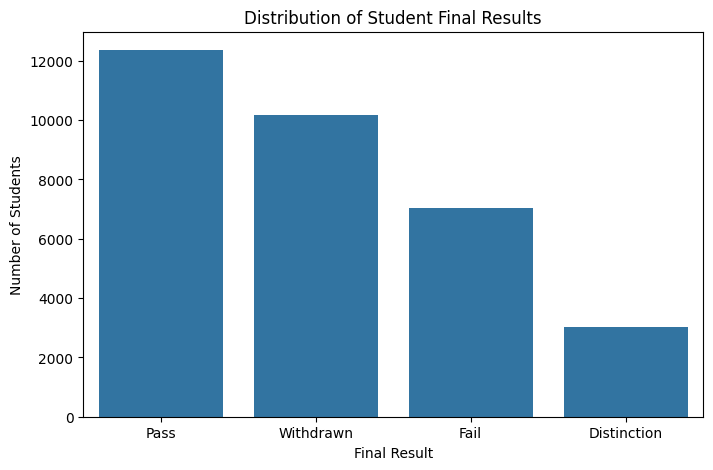

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=student_info,
    x="final_result",
    order=student_info["final_result"].value_counts().index
)

plt.title("Distribution of Student Final Results")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.show()

In [13]:
# Check for special missing-value markers

for column in student_info.columns:
    count = (student_info[column] == "?").sum()

    if count > 0:
        print(column, ":", count, "special missing values")

imd_band : 1111 special missing values


In [14]:
print("Missing IMD values:")
print((student_info["imd_band"] == "?").sum())

print("\nAvailable IMD values:")
print((student_info["imd_band"] != "?").sum())

print("\nPercentage missing:")
print(
    (student_info["imd_band"] == "?").mean() * 100
)

Missing IMD values:
1111

Available IMD values:
31482

Percentage missing:
3.408707391157611


In [15]:
student_info["imd_band"].value_counts()

imd_band
20-30%     3654
30-40%     3539
10-20      3516
0-10%      3311
40-50%     3256
50-60%     3124
60-70%     2905
70-80%     2879
80-90%     2762
90-100%    2536
?          1111
Name: count, dtype: int64

In [16]:
# Check for completely identical rows

print("Exact duplicate rows:", student_info.duplicated().sum())

Exact duplicate rows: 0


In [17]:
# Check whether a student has multiple records
# for the same course presentation

duplicate_records = student_info.duplicated(
    subset=["id_student", "code_module", "code_presentation"]
)

print("Duplicate student-course records:", duplicate_records.sum())

Duplicate student-course records: 0


## Dataset Exploration — Student Information

- Total records: 32,593
- Total columns: 12
- Numerical columns: 3
- Categorical columns: 9
- Actual null values: 0
- Special missing values in imd_band: 1,111
- Percentage of missing IMD values: 3.41%
- Exact duplicate rows: 0
- Duplicate student-course records: 0

### Initial Observations
1. The dataset contains four final outcome categories.
2. Pass is the most frequent outcome.
3. Withdrawn is the second most frequent outcome.
4. The imd_band column contains special missing-value markers.
5. No duplicate student-course records were detected.

In [18]:
student_assessment.isnull().sum()

id_assessment     0
id_student        0
date_submitted    0
is_banked         0
score             0
dtype: int64

In [19]:
student_assessment["score"].describe()

count     173912
unique       102
top          100
freq       18813
Name: score, dtype: object

In [20]:
student_assessment[
    (student_assessment["score"] < 0) |
    (student_assessment["score"] > 100)
]

TypeError: '<' not supported between instances of 'str' and 'int'

In [21]:
print(student_assessment["score"].dtype)

object


In [22]:
student_assessment["score"].unique()[:20]

array(['78', '70', '72', '69', '79', '71', '68', '73', '67', '83', '66',
       '59', '82', '60', '75', '74', '62', '63', '84', '80'], dtype=object)

In [23]:
numeric_scores = pd.to_numeric(
    student_assessment["score"],
    errors="coerce"
)

print("Values that cannot be converted:", numeric_scores.isna().sum())

Values that cannot be converted: 173


In [24]:
invalid_scores = student_assessment.loc[
    numeric_scores.isna(),
    "score"
]

print("Number of non-numeric score entries:", len(invalid_scores))
print("\nValues and their counts:")
print(invalid_scores.value_counts(dropna=False))

Number of non-numeric score entries: 173

Values and their counts:
score
?    173
Name: count, dtype: int64


In [25]:
student_assessment["score_numeric"] = pd.to_numeric(
    student_assessment["score"].replace("?", pd.NA),
    errors="coerce"
)

print("Missing numeric scores:", student_assessment["score_numeric"].isna().sum())
print("\nNumeric score summary:")
print(student_assessment["score_numeric"].describe())

Missing numeric scores: 173

Numeric score summary:
count    173739.000000
mean         75.799573
std          18.798107
min           0.000000
25%          65.000000
50%          80.000000
75%          90.000000
max         100.000000
Name: score_numeric, dtype: float64


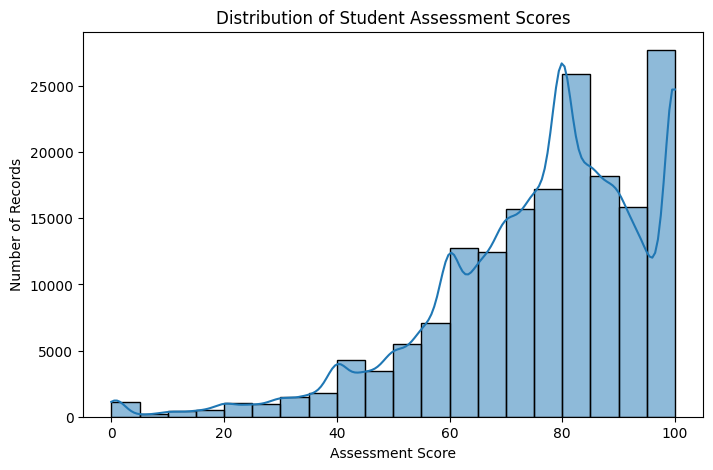

In [26]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=student_assessment,
    x="score_numeric",
    bins=20,
    kde=True
)

plt.title("Distribution of Student Assessment Scores")
plt.xlabel("Assessment Score")
plt.ylabel("Number of Records")
plt.show()

In [27]:
print("Shape:", assessments.shape)

print("\nFirst 5 rows:")
display(assessments.head())

print("\nDataset information:")
assessments.info()

print("\nMissing values:")
print(assessments.isnull().sum())


Shape: (206, 6)

First 5 rows:


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19,10.0
1,AAA,2013J,1753,TMA,54,20.0
2,AAA,2013J,1754,TMA,117,20.0
3,AAA,2013J,1755,TMA,166,20.0
4,AAA,2013J,1756,TMA,215,30.0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   code_module        206 non-null    object 
 1   code_presentation  206 non-null    object 
 2   id_assessment      206 non-null    int64  
 3   assessment_type    206 non-null    object 
 4   date               206 non-null    object 
 5   weight             206 non-null    float64
dtypes: float64(1), int64(1), object(4)
memory usage: 9.8+ KB

Missing values:
code_module          0
code_presentation    0
id_assessment        0
assessment_type      0
date                 0
weight               0
dtype: int64


In [28]:
print("Assessment types and counts:")
print(assessments["assessment_type"].value_counts(dropna=False))

print("\nDate values that are not numeric:")
numeric_dates = pd.to_numeric(assessments["date"], errors="coerce")
print(assessments.loc[numeric_dates.isna(), "date"].value_counts(dropna=False))

print("\nAssessment weight summary:")
print(assessments["weight"].describe())

Assessment types and counts:
assessment_type
TMA     106
CMA      76
Exam     24
Name: count, dtype: int64

Date values that are not numeric:
date
?    11
Name: count, dtype: int64

Assessment weight summary:
count    206.000000
mean      20.873786
std       30.384224
min        0.000000
25%        0.000000
50%       12.500000
75%       24.250000
max      100.000000
Name: weight, dtype: float64


In [29]:
print("Assessments with missing dates:")
display(assessments[assessments["date"] == "?"])

print("\nAssessments with zero weight:")
display(assessments[assessments["weight"] == 0])

Assessments with missing dates:


,code_module,code_presentation,id_assessment,assessment_type,date,weight
5,AAA,2013J,1757,Exam,?,100.0
11,AAA,2014J,1763,Exam,?,100.0
23,BBB,2013B,14990,Exam,?,100.0
35,BBB,2013J,15002,Exam,?,100.0
47,BBB,2014B,15014,Exam,?,100.0
53,BBB,2014J,15025,Exam,?,100.0
62,CCC,2014B,24290,Exam,?,100.0
63,CCC,2014B,40087,Exam,?,100.0
72,CCC,2014J,24299,Exam,?,100.0
73,CCC,2014J,40088,Exam,?,100.0



Assessments with zero weight:


,code_module,code_presentation,id_assessment,assessment_type,date,weight
48,BBB,2014J,15020,TMA,19,0.0
124,FFF,2013B,34865,CMA,222,0.0
125,FFF,2013B,34866,CMA,222,0.0
126,FFF,2013B,34867,CMA,222,0.0
127,FFF,2013B,34868,CMA,222,0.0
128,FFF,2013B,34869,CMA,222,0.0
129,FFF,2013B,34871,CMA,222,0.0
130,FFF,2013B,34870,CMA,222,0.0
137,FFF,2013J,34878,CMA,236,0.0
138,FFF,2013J,34879,CMA,236,0.0


In [30]:
print("Shape:", courses.shape)

print("\nFirst 5 rows:")
display(courses.head())

print("\nDataset information:")
courses.info()

print("\nMissing values:")
print(courses.isnull().sum())

print("\nDuplicate rows:")
print(courses.duplicated().sum())

Shape: (22, 3)

First 5 rows:


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   code_module                 22 non-null     object
 1   code_presentation           22 non-null     object
 2   module_presentation_length  22 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 656.0+ bytes

Missing values:
code_module                   0
code_presentation             0
module_presentation_length    0
dtype: int64

Duplicate rows:
0


In [31]:
print("Shape:", student_registration.shape)

print("\nFirst 5 rows:")
display(student_registration.head())

print("\nDataset information:")
student_registration.info()

print("\nMissing values:")
print(student_registration.isnull().sum())

print("\nSpecial missing-value markers:")
for column in student_registration.columns:
    count = (student_registration[column] == "?").sum()
    if count > 0:
        print(f"{column}: {count}")

Shape: (32593, 5)

First 5 rows:


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159,?
1,AAA,2013J,28400,-53,?
2,AAA,2013J,30268,-92,12
3,AAA,2013J,31604,-52,?
4,AAA,2013J,32885,-176,?



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   code_module          32593 non-null  object
 1   code_presentation    32593 non-null  object
 2   id_student           32593 non-null  int64 
 3   date_registration    32593 non-null  object
 4   date_unregistration  32593 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.2+ MB

Missing values:
code_module            0
code_presentation      0
id_student             0
date_registration      0
date_unregistration    0
dtype: int64

Special missing-value markers:
date_registration: 45
date_unregistration: 22521


In [32]:
print("Rows with missing registration dates:")
display(
    student_registration[
        student_registration["date_registration"] == "?"
    ].head(10)
)

print("\nCount of records with a recorded withdrawal date:")
print(
    (student_registration["date_unregistration"] != "?").sum()
)

Rows with missing registration dates:


,code_module,code_presentation,id_student,date_registration,date_unregistration
2344,BBB,2013B,630346,?,?
2538,BBB,2013J,57369,?,-1
2759,BBB,2013J,342678,?,-33
5356,BBB,2014B,582496,?,-126
5490,BBB,2014B,607646,?,-38
5573,BBB,2014B,614270,?,-142
6295,BBB,2014B,2409808,?,-109
6305,BBB,2014B,2439442,?,-149
8307,BBB,2014J,694001,?,-36
8975,CCC,2014B,394791,?,-61



Count of records with a recorded withdrawal date:
10072


In [33]:
assessment_details = student_assessment.merge(
    assessments[["id_assessment", "assessment_type"]],
    on="id_assessment",
    how="left"
)

print("Assessment records by type:")
print(assessment_details["assessment_type"].value_counts(dropna=False))

print("\nNumber of records without a matching assessment type:")
print(assessment_details["assessment_type"].isna().sum())

Assessment records by type:
assessment_type
TMA     98426
CMA     70527
Exam     4959
Name: count, dtype: int64

Number of records without a matching assessment type:
0


In [34]:
print("Unique students in student_assessment:")
print(student_assessment["id_student"].nunique())

print("\nUnique assessments:")
print(student_assessment["id_assessment"].nunique())

print("\nRecords per student (summary):")
print(student_assessment.groupby("id_student").size().describe())

Unique students in student_assessment:
23369

Unique assessments:
188

Records per student (summary):
count    23369.000000
mean         7.441996
std          4.223937
min          1.000000
25%          4.000000
50%          7.000000
75%         11.000000
max         28.000000
dtype: float64


In [35]:
print(
    "Duplicate student-assessment pairs:",
    student_assessment.duplicated(
        subset=["id_student", "id_assessment"]
    ).sum()
)

Duplicate student-assessment pairs: 0


In [36]:
student_vle_path = DATA_DIR / "studentVle.csv"

print("File exists:", student_vle_path.exists())
print("File size in MB:", round(student_vle_path.stat().st_size / (1024 * 1024), 2))

File exists: True
File size in MB: 432.81


In [37]:
student_vle_sample = pd.read_csv(
    student_vle_path,
    nrows=5
)

display(student_vle_sample)

print("\nColumns:")
print(student_vle_sample.columns.tolist())

,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1



Columns:
['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']


In [38]:
chunk_size = 100_000

total_rows = 0
unique_students = set()
total_clicks = 0
min_date = None
max_date = None

for chunk in pd.read_csv(student_vle_path, chunksize=chunk_size):
    total_rows += len(chunk)
    unique_students.update(chunk["id_student"].unique())
    total_clicks += chunk["sum_click"].sum()

    chunk_min = chunk["date"].min()
    chunk_max = chunk["date"].max()

    min_date = chunk_min if min_date is None else min(min_date, chunk_min)
    max_date = chunk_max if max_date is None else max(max_date, chunk_max)

print("Total rows:", total_rows)
print("Unique students:", len(unique_students))
print("Total clicks:", total_clicks)
print("Minimum date:", min_date)
print("Maximum date:", max_date)

Total rows: 10655280
Unique students: 26074
Total clicks: 39605099
Minimum date: -25
Maximum date: 269


In [40]:
missing_markers = {
    "date_question_marks": 0,
    "sum_click_question_marks": 0,
    "negative_click_values": 0
}

for chunk in pd.read_csv(
    student_vle_path,
    chunksize=100_000,
    dtype={"date": "string", "sum_click": "string"}
):
    missing_markers["date_question_marks"] += (
        chunk["date"] == "?"
    ).sum()

    missing_markers["sum_click_question_marks"] += (
        chunk["sum_click"] == "?"
    ).sum()

    numeric_clicks = pd.to_numeric(
        chunk["sum_click"],
        errors="coerce"
    )

    missing_markers["negative_click_values"] += (
        numeric_clicks < 0
    ).sum()

print(missing_markers)

{'date_question_marks': 0, 'sum_click_question_marks': 0, 'negative_click_values': 0}


In [41]:
datasets = {
    "student_info": student_info,
    "student_registration": student_registration,
    "student_assessment": student_assessment,
    "assessments": assessments,
    "courses": courses,
    "vle": vle,
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


student_info: (32593, 12)
student_registration: (32593, 5)
student_assessment: (173912, 6)
assessments: (206, 6)
courses: (22, 3)
vle: (6364, 6)


In [42]:
print("Student records:", len(student_info))
print(
    "Unique student-course-presentation combinations:",
    student_info[
        ["id_student", "code_module", "code_presentation"]
    ].drop_duplicates().shape[0]
)

print("\nStudent assessment IDs matching student_info:")
print(
    student_assessment["id_student"].isin(
        student_info["id_student"]
    ).sum(),
    "out of",
    len(student_assessment)
)

Student records: 32593
Unique student-course-presentation combinations: 32593

Student assessment IDs matching student_info:
173912 out of 173912


In [43]:
# Step 3.1: Inspect registration information for Day 28 cohort creation

student_registration.head()

,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159,?
1,AAA,2013J,28400,-53,?
2,AAA,2013J,30268,-92,12
3,AAA,2013J,31604,-52,?
4,AAA,2013J,32885,-176,?


In [44]:
student_registration.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   code_module          32593 non-null  object
 1   code_presentation    32593 non-null  object
 2   id_student           32593 non-null  int64 
 3   date_registration    32593 non-null  object
 4   date_unregistration  32593 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.2+ MB


In [45]:
student_registration["date_registration"].value_counts(dropna=False).head(10)

date_registration
-22    1034
-29     982
-24     741
-25     730
-23     729
-30     581
-36     553
-28     548
-32     497
-17     488
Name: count, dtype: int64

In [46]:
student_registration["date_unregistration"].value_counts(dropna=False).head(10)

date_unregistration
?     22521
12      788
0       419
27      170
-1      147
-7       99
-2       99
10       91
-5       90
-8       87
Name: count, dtype: int64

In [47]:
import pandas as pd

# Make a copy so the original dataset stays unchanged
registration = student_registration.copy()

# Convert date columns from text to numbers.
# The "?" values become missing values (NaN).
registration["date_registration_num"] = pd.to_numeric(
    registration["date_registration"].replace("?", pd.NA),
    errors="coerce"
)

registration["date_unregistration_num"] = pd.to_numeric(
    registration["date_unregistration"].replace("?", pd.NA),
    errors="coerce"
)

# A student is excluded if their recorded withdrawal happened
# on or before Day 28.
# Missing withdrawal date or withdrawal after Day 28 = eligible.
registration["eligible_day28"] = (
    registration["date_unregistration_num"].isna()
    | (registration["date_unregistration_num"] > 28)
)

# Keep only eligible student-course-presentation records
cohort_day28 = registration.loc[
    registration["eligible_day28"]
].copy()

print("Original registration records:", len(registration))
print("Eligible Day 28 records:", len(cohort_day28))
print("Excluded (withdrew on/before Day 28):",
      (~registration["eligible_day28"]).sum())

cohort_day28.head()

Original registration records: 32593
Eligible Day 28 records: 27538
Excluded (withdrew on/before Day 28): 5055


,code_module,code_presentation,id_student,date_registration,date_unregistration,date_registration_num,date_unregistration_num,eligible_day28
0,AAA,2013J,11391,-159,?,-159.0,NaN,True
1,AAA,2013J,28400,-53,?,-53.0,NaN,True
3,AAA,2013J,31604,-52,?,-52.0,NaN,True
4,AAA,2013J,32885,-176,?,-176.0,NaN,True
5,AAA,2013J,38053,-110,?,-110.0,NaN,True


In [48]:
print(
    "Missing registration dates:",
    registration["date_registration_num"].isna().sum()
)

print(
    "Registered after Day 28:",
    (registration["date_registration_num"] > 28).sum()
)

print(
    "Registered on or before Day 28:",
    (registration["date_registration_num"] <= 28).sum()
)

Missing registration dates: 45
Registered after Day 28: 16
Registered on or before Day 28: 32532


In [49]:
# Keep records with a known registration date on or before Day 28
registered_by_day28 = (
    registration["date_registration_num"].notna()
    & (registration["date_registration_num"] <= 28)
)

# Keep students who had not withdrawn by Day 28
not_withdrawn_by_day28 = (
    registration["date_unregistration_num"].isna()
    | (registration["date_unregistration_num"] > 28)
)

# Apply both eligibility conditions
cohort_day28 = registration.loc[
    registered_by_day28 & not_withdrawn_by_day28
].copy()

print("Final Day 28 cohort:", len(cohort_day28))
print("Missing registration dates excluded:",
      registration["date_registration_num"].isna().sum())
print("Registered after Day 28 excluded:",
      (registration["date_registration_num"] > 28).sum())
print("Withdrawn on/before Day 28 excluded:",
      (registration["date_unregistration_num"] <= 28).sum())

Final Day 28 cohort: 27515
Missing registration dates excluded: 45
Registered after Day 28 excluded: 16
Withdrawn on/before Day 28 excluded: 5055


In [50]:
# Keep only the identifiers and target from student_info
outcomes = student_info[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "final_result"
    ]
].copy()

# Attach outcomes to the eligible Day 28 cohort
cohort_day28 = cohort_day28.merge(
    outcomes,
    on=["id_student", "code_module", "code_presentation"],
    how="left",
    validate="one_to_one"
)

print("Cohort records after outcome merge:", len(cohort_day28))
print("Missing final outcomes:", cohort_day28["final_result"].isna().sum())

print("\nTarget distribution:")
print(cohort_day28["final_result"].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    (cohort_day28["final_result"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Cohort records after outcome merge: 27515
Missing final outcomes: 0

Target distribution:
final_result
Pass           12355
Fail            7032
Withdrawn       5105
Distinction     3023
Name: count, dtype: int64

Target percentages:
final_result
Pass           44.90
Fail           25.56
Withdrawn      18.55
Distinction    10.99
Name: proportion, dtype: float64


In [51]:
# Step 3.4: Prepare assessment records for the Day 28 cutoff

# Copy the assessment data
assessment_records = student_assessment.copy()

# Convert submission dates to numeric values
assessment_records["date_submitted_num"] = pd.to_numeric(
    assessment_records["date_submitted"].replace("?", pd.NA),
    errors="coerce"
)

# Keep only submissions available by the end of Day 28
early_assessments = assessment_records[
    assessment_records["date_submitted_num"].notna()
    & (assessment_records["date_submitted_num"] <= 28)
].copy()

print("All assessment records:", len(assessment_records))
print("Assessment records submitted by Day 28:", len(early_assessments))

early_assessments.head()

All assessment records: 173912
Assessment records submitted by Day 28: 25614


,id_assessment,id_student,date_submitted,is_banked,score,score_numeric,date_submitted_num
0,1752,11391,18,0,78,78.0,18
1,1752,28400,22,0,70,70.0,22
2,1752,31604,17,0,72,72.0,17
3,1752,32885,26,0,69,69.0,26
4,1752,38053,19,0,79,79.0,19


In [52]:
# Attach module, presentation, and assessment type
early_assessments = early_assessments.merge(
    assessments[
        ["id_assessment", "code_module", "code_presentation", "assessment_type"]
    ],
    on="id_assessment",
    how="left",
    validate="many_to_one"
)

# Keep only records belonging to our eligible Day 28 cohort
early_assessments = early_assessments.merge(
    cohort_day28[
        ["id_student", "code_module", "code_presentation"]
    ],
    on=["id_student", "code_module", "code_presentation"],
    how="inner",
    validate="many_to_one"
)

print("Eligible early assessment records:", len(early_assessments))
print("Missing assessment types:", early_assessments["assessment_type"].isna().sum())

early_assessments.head()

Eligible early assessment records: 25081
Missing assessment types: 0


,id_assessment,id_student,date_submitted,is_banked,score,score_numeric,date_submitted_num,code_module,code_presentation,assessment_type
0,1752,11391,18,0,78,78.0,18,AAA,2013J,TMA
1,1752,28400,22,0,70,70.0,22,AAA,2013J,TMA
2,1752,31604,17,0,72,72.0,17,AAA,2013J,TMA
3,1752,32885,26,0,69,69.0,26,AAA,2013J,TMA
4,1752,38053,19,0,79,79.0,19,AAA,2013J,TMA


In [53]:
assessment_features = (
    early_assessments
    .groupby(["id_student", "code_module", "code_presentation"])
    .agg(
        early_assessment_count=("id_assessment", "count"),
        early_mean_score=("score_numeric", "mean"),
        early_max_score=("score_numeric", "max"),
        early_min_score=("score_numeric", "min")
    )
    .reset_index()
)

print("Students with at least one early assessment:", len(assessment_features))
assessment_features.head()

Students with at least one early assessment: 20401


,id_student,code_module,code_presentation,early_assessment_count,early_mean_score,early_max_score,early_min_score
0,6516,AAA,2014J,1,60.0,60.0,60.0
1,11391,AAA,2013J,1,78.0,78.0,78.0
2,23629,BBB,2013B,1,67.0,67.0,67.0
3,23698,CCC,2014J,1,78.0,78.0,78.0
4,23798,BBB,2013J,1,90.0,90.0,90.0


In [54]:
from pathlib import Path

possible_paths = [
    Path("../data/raw/studentVle.csv"),
    Path("data/raw/studentVle.csv"),
]

vle_path = next((p for p in possible_paths if p.exists()), None)

if vle_path is None:
    raise FileNotFoundError(
        "Could not find studentVle.csv. Check that the notebook is inside "
        "EduGuard_AI/notebooks and the CSV is inside data/raw."
    )

print("Using file:", vle_path.resolve())

Using file: C:\Users\User\Desktop\EduGuard_AI\data\raw\studentVle.csv


In [55]:
import pandas as pd

chunk_size = 100_000

# Keep only cohort identifiers for matching
cohort_keys = cohort_day28[
    ["id_student", "code_module", "code_presentation"]
].drop_duplicates()

click_parts = []
active_day_parts = []
site_parts = []

for chunk in pd.read_csv(vle_path, chunksize=chunk_size):

    # Keep activity recorded by the end of Day 28
    chunk = chunk[chunk["date"] <= 28].copy()

    if chunk.empty:
        continue

    # Keep only activity belonging to our eligible cohort
    chunk = chunk.merge(
        cohort_keys,
        on=["id_student", "code_module", "code_presentation"],
        how="inner",
        validate="many_to_one"
    )

    if chunk.empty:
        continue

    keys = ["id_student", "code_module", "code_presentation"]

    # Total clicks by student/course/presentation
    click_parts.append(
        chunk.groupby(keys, as_index=False)["sum_click"]
        .sum()
        .rename(columns={"sum_click": "early_total_clicks"})
    )

    # Record student activity by day; duplicates are removed later
    active_day_parts.append(
        chunk[keys + ["date"]].drop_duplicates()
    )

    # Record which VLE sites each student accessed
    site_parts.append(
        chunk[keys + ["id_site"]].drop_duplicates()
    )

print("Finished reading and filtering VLE chunks.")
print("Click summary chunks:", len(click_parts))
print("Active-day chunks:", len(active_day_parts))
print("Site chunks:", len(site_parts))

Finished reading and filtering VLE chunks.
Click summary chunks: 47
Active-day chunks: 47
Site chunks: 47


In [56]:
keys = ["id_student", "code_module", "code_presentation"]

# Combine total clicks across chunks
vle_click_features = (
    pd.concat(click_parts, ignore_index=True)
    .groupby(keys, as_index=False)["early_total_clicks"]
    .sum()
)

# Count distinct active days
vle_active_day_features = (
    pd.concat(active_day_parts, ignore_index=True)
    .drop_duplicates(keys + ["date"])
    .groupby(keys, as_index=False)
    .size()
    .rename(columns={"size": "early_active_days"})
)

# Count distinct VLE sites accessed
vle_site_features = (
    pd.concat(site_parts, ignore_index=True)
    .drop_duplicates(keys + ["id_site"])
    .groupby(keys, as_index=False)
    .size()
    .rename(columns={"size": "early_unique_sites"})
)

# Combine the three VLE feature summaries
vle_features = (
    vle_click_features
    .merge(vle_active_day_features, on=keys, how="outer", validate="one_to_one")
    .merge(vle_site_features, on=keys, how="outer", validate="one_to_one")
)

print("Students with VLE activity by Day 28:", len(vle_features))
vle_features.head()

Students with VLE activity by Day 28: 26617


,id_student,code_module,code_presentation,early_total_clicks,early_active_days,early_unique_sites
0,6516,AAA,2014J,826,28,36
1,8462,DDD,2013J,375,20,76
2,11391,AAA,2013J,401,8,24
3,23629,BBB,2013B,53,6,7
4,23698,CCC,2014J,365,30,21


In [57]:
keys = ["id_student", "code_module", "code_presentation"]

# Start with the complete eligible cohort and its target
model_data = cohort_day28[
    keys + ["date_registration_num", "final_result"]
].copy()

# Add early assessment features
model_data = model_data.merge(
    assessment_features,
    on=keys,
    how="left",
    validate="one_to_one"
)

# Add early VLE features
model_data = model_data.merge(
    vle_features,
    on=keys,
    how="left",
    validate="one_to_one"
)

# Add student background features
background_columns = [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability"
]

background_features = student_info[
    keys + background_columns
].copy()

model_data = model_data.merge(
    background_features,
    on=keys,
    how="left",
    validate="one_to_one"
)

# Students with no recorded early activity have zero activity counts
count_columns = [
    "early_assessment_count",
    "early_total_clicks",
    "early_active_days",
    "early_unique_sites"
]

model_data[count_columns] = model_data[count_columns].fillna(0)

print("Rows in combined dataset:", len(model_data))
print("Columns in combined dataset:", len(model_data.columns))
print("\nMissing values per column:")
print(model_data.isna().sum())

model_data.head()

Rows in combined dataset: 27515
Columns in combined dataset: 20

Missing values per column:
id_student                   0
code_module                  0
code_presentation            0
date_registration_num        0
final_result                 0
early_assessment_count       0
early_mean_score          7120
early_max_score           7120
early_min_score           7120
early_total_clicks           0
early_active_days            0
early_unique_sites           0
gender                       0
region                       0
highest_education            0
imd_band                     0
age_band                     0
num_of_prev_attempts         0
studied_credits              0
disability                   0
dtype: int64


,id_student,code_module,code_presentation,date_registration_num,final_result,early_assessment_count,early_mean_score,early_max_score,early_min_score,early_total_clicks,early_active_days,early_unique_sites,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability
0,11391,AAA,2013J,-159.0,Pass,1.0,78.0,78.0,78.0,401.0,8.0,24.0,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N
1,28400,AAA,2013J,-53.0,Pass,1.0,70.0,70.0,70.0,618.0,19.0,34.0,F,Scotland,HE Qualification,20-30%,35-55,0,60,N
2,31604,AAA,2013J,-52.0,Pass,1.0,72.0,72.0,72.0,494.0,22.0,31.0,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N
3,32885,AAA,2013J,-176.0,Pass,1.0,69.0,69.0,69.0,567.0,24.0,34.0,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N
4,38053,AAA,2013J,-110.0,Pass,1.0,79.0,79.0,79.0,727.0,32.0,30.0,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N


In [58]:
# Check whether missing scores mean no early assessment,
# or an assessment record exists but its score is missing.

print("Rows with no early assessment:")
print((model_data["early_assessment_count"] == 0).sum())

print("\nRows with missing early mean score:")
print(model_data["early_mean_score"].isna().sum())

print("\nRows with an assessment count but missing mean score:")
print(
    (
        (model_data["early_assessment_count"] > 0)
        & model_data["early_mean_score"].isna()
    ).sum()
)

print("\nRows with an assessment count and a valid mean score:")
print(
    (
        (model_data["early_assessment_count"] > 0)
        & model_data["early_mean_score"].notna()
    ).sum()
)

Rows with no early assessment:
7114

Rows with missing early mean score:
7120

Rows with an assessment count but missing mean score:
6

Rows with an assessment count and a valid mean score:
20395


In [59]:
background_columns = [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

for column in background_columns:
    print(f"\n{column}:")
    print(model_data[column].value_counts(dropna=False).head(10))


gender:
gender
M    15164
F    12351
Name: count, dtype: int64

region:
region
Scotland                3160
East Anglian Region     2803
South Region            2622
London Region           2572
North Western Region    2331
West Midlands Region    2088
South West Region       2051
East Midlands Region    1922
Wales                   1910
South East Region       1767
Name: count, dtype: int64

highest_education:
highest_education
A Level or Equivalent          12033
Lower Than A Level             10789
HE Qualification                4145
Post Graduate Qualification      288
No Formal quals                  260
Name: count, dtype: int64

imd_band:
imd_band
30-40%     2997
20-30%     2979
10-20      2823
40-50%     2714
50-60%     2688
0-10%      2646
70-80%     2515
60-70%     2509
80-90%     2377
90-100%    2240
Name: count, dtype: int64

age_band:
age_band
0-35     19166
35-55     8156
55<=       193
Name: count, dtype: int64

disability:
disability
N    24908
Y     2607
Name: count,

In [60]:
# Inspect students who have early assessment records but no numeric score

six_records = model_data[
    (model_data["early_assessment_count"] > 0)
    & model_data["early_mean_score"].isna()
]

six_records[
    keys + [
        "early_assessment_count",
        "early_mean_score",
        "early_max_score",
        "early_min_score"
    ]
]

,id_student,code_module,code_presentation,early_assessment_count,early_mean_score,early_max_score,early_min_score
1430,531205,BBB,2013B,1.0,NaN,NaN,NaN
4662,606501,BBB,2014B,1.0,NaN,NaN,NaN
6521,678578,BBB,2014J,1.0,NaN,NaN,NaN
12165,427248,DDD,2013J,1.0,NaN,NaN,NaN
18568,174436,FFF,2013B,1.0,NaN,NaN,NaN
19996,126074,FFF,2013J,1.0,NaN,NaN,NaN


In [61]:
background_columns = [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

for column in background_columns:
    print(f"{column}: {(model_data[column] == '?').sum()} '?' values")

gender: 0 '?' values
region: 0 '?' values
highest_education: 0 '?' values
imd_band: 1027 '?' values
age_band: 0 '?' values
disability: 0 '?' values


In [62]:
print("Columns:", six_records.columns.tolist())

print(
    six_records[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "early_assessment_count",
            "early_mean_score",
            "early_max_score",
            "early_min_score"
        ]
    ].to_string(index=False)
)

Columns: ['id_student', 'code_module', 'code_presentation', 'date_registration_num', 'final_result', 'early_assessment_count', 'early_mean_score', 'early_max_score', 'early_min_score', 'early_total_clicks', 'early_active_days', 'early_unique_sites', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']
 id_student code_module code_presentation  early_assessment_count  early_mean_score  early_max_score  early_min_score
     531205         BBB             2013B                     1.0               NaN              NaN              NaN
     606501         BBB             2014B                     1.0               NaN              NaN              NaN
     678578         BBB             2014J                     1.0               NaN              NaN              NaN
     427248         DDD             2013J                     1.0               NaN              NaN              NaN
     174436         FFF             20

In [63]:
six_keys = six_records[
    ["id_student", "code_module", "code_presentation"]
]

six_source_records = early_assessments.merge(
    six_keys,
    on=["id_student", "code_module", "code_presentation"],
    how="inner"
)

print(
    six_source_records[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "id_assessment",
            "date_submitted_num",
            "score",
            "score_numeric"
        ]
    ].to_string(index=False)
)

 id_student code_module code_presentation  id_assessment  date_submitted_num score  score_numeric
     531205         BBB             2013B          14984                  26     ?            NaN
     606501         BBB             2014B          15008                  11     ?            NaN
     678578         BBB             2014J          15020                  19     ?            NaN
     427248         DDD             2013J          25348                  25     ?            NaN
     174436         FFF             2013B          34860                  13     ?            NaN
     126074         FFF             2013J          34873                  20     ?            NaN


In [64]:
print(
    six_source_records[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "id_assessment",
            "date_submitted_num",
            "score",
            "score_numeric"
        ]
    ].to_string(index=False)
)

 id_student code_module code_presentation  id_assessment  date_submitted_num score  score_numeric
     531205         BBB             2013B          14984                  26     ?            NaN
     606501         BBB             2014B          15008                  11     ?            NaN
     678578         BBB             2014J          15020                  19     ?            NaN
     427248         DDD             2013J          25348                  25     ?            NaN
     174436         FFF             2013B          34860                  13     ?            NaN
     126074         FFF             2013J          34873                  20     ?            NaN


In [65]:
# Keep identifiers separately for later prediction tracking
record_ids = model_data[
    ["id_student", "code_module", "code_presentation"]
].copy()

# Create a modeling copy
clean_data = model_data.copy()

# Convert OULAD's "?" marker to a true missing value
clean_data["imd_band"] = clean_data["imd_band"].replace("?", pd.NA)

# Remove student ID from model inputs
clean_data = clean_data.drop(columns=["id_student"])

print("Clean dataset shape:", clean_data.shape)
print("\nMissing values:")
print(clean_data.isna().sum())

print("\nTarget values:")
print(clean_data["final_result"].value_counts())

Clean dataset shape: (27515, 19)

Missing values:
code_module                  0
code_presentation            0
date_registration_num        0
final_result                 0
early_assessment_count       0
early_mean_score          7120
early_max_score           7120
early_min_score           7120
early_total_clicks           0
early_active_days            0
early_unique_sites           0
gender                       0
region                       0
highest_education            0
imd_band                  1027
age_band                     0
num_of_prev_attempts         0
studied_credits              0
disability                   0
dtype: int64

Target values:
final_result
Pass           12355
Fail            7032
Withdrawn       5105
Distinction     3023
Name: count, dtype: int64


In [66]:
# Separate target from model input features
X = clean_data.drop(columns=["final_result"])
y = clean_data["final_result"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Feature matrix shape: (27515, 18)
Target shape: (27515,)

Target classes:
final_result
Pass           12355
Fail            7032
Withdrawn       5105
Distinction     3023
Name: count, dtype: int64

Feature columns:
['code_module', 'code_presentation', 'date_registration_num', 'early_assessment_count', 'early_mean_score', 'early_max_score', 'early_min_score', 'early_total_clicks', 'early_active_days', 'early_unique_sites', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']


In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (22012, 18)
Testing features: (5503, 18)

Training target distribution (%):
final_result
Pass           44.90
Fail           25.56
Withdrawn      18.55
Distinction    10.98
Name: proportion, dtype: float64

Testing target distribution (%):
final_result
Pass           44.90
Fail           25.55
Withdrawn      18.55
Distinction    10.99
Name: proportion, dtype: float64


In [68]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Numeric features
numeric_features = [
    "date_registration_num",
    "early_assessment_count",
    "early_mean_score",
    "early_max_score",
    "early_min_score",
    "early_total_clicks",
    "early_active_days",
    "early_unique_sites",
    "num_of_prev_attempts",
    "studied_credits"
]

# Categorical features
categorical_features = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

# Preprocess numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing for both feature types
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print("Preprocessing and Random Forest pipeline created successfully.")

Preprocessing and Random Forest pipeline created successfully.


In [69]:
model_pipeline.fit(X_train, y_train)

print("Baseline Random Forest model trained successfully!")

TypeError: boolean value of NA is ambiguous

In [70]:
try:
    model_pipeline.fit(X_train, y_train)
    print("Baseline Random Forest model trained successfully!")

except Exception as error:
    print("Error type:", type(error).__name__)
    print("Error details:", error)
    raise

Error type: TypeError
Error details: boolean value of NA is ambiguous


TypeError: boolean value of NA is ambiguous

In [71]:
import numpy as np

# Convert pandas missing markers to NumPy NaN in categorical columns
for column in categorical_features:
    X_train[column] = X_train[column].astype(object).where(
        X_train[column].notna(),
        np.nan
    )

    X_test[column] = X_test[column].astype(object).where(
        X_test[column].notna(),
        np.nan
    )

print("Categorical missing values standardized.")
print("Missing values in training categorical features:")
print(X_train[categorical_features].isna().sum())

Categorical missing values standardized.
Missing values in training categorical features:
code_module            0
code_presentation      0
gender                 0
region                 0
highest_education      0
imd_band             820
age_band               0
disability             0
dtype: int64


In [72]:
model_pipeline.fit(X_train, y_train)

print("Baseline Random Forest model trained successfully!")

Baseline Random Forest model trained successfully!


In [73]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict outcomes for the test set
y_pred = model_pipeline.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Macro F1-score:    {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:          0.5263
Balanced Accuracy: 0.3953
Macro F1-score:    0.4056

Classification Report:
              precision    recall  f1-score   support

 Distinction       0.49      0.17      0.25       605
        Fail       0.50      0.38      0.43      1406
        Pass       0.54      0.83      0.66      2471
   Withdrawn       0.49      0.20      0.29      1021

    accuracy                           0.53      5503
   macro avg       0.50      0.40      0.41      5503
weighted avg       0.51      0.53      0.48      5503



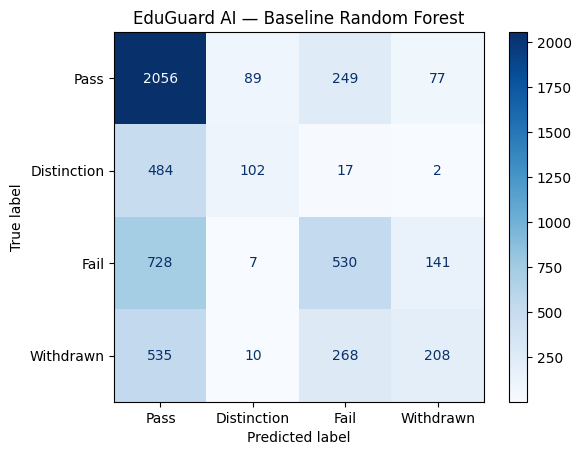

In [74]:
class_labels = ["Pass", "Distinction", "Fail", "Withdrawn"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("EduGuard AI — Baseline Random Forest")
plt.show()

In [75]:
# Recover student IDs for the records in each split.
# The original row indexes are preserved by train_test_split.

train_student_ids = set(
    record_ids.loc[X_train.index, "id_student"]
)

test_student_ids = set(
    record_ids.loc[X_test.index, "id_student"]
)

overlap_student_ids = train_student_ids.intersection(test_student_ids)

print("Unique students in training:", len(train_student_ids))
print("Unique students in testing:", len(test_student_ids))
print("Students appearing in both sets:", len(overlap_student_ids))

Unique students in training: 20289
Unique students in testing: 5385
Students appearing in both sets: 848


In [76]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# Each student's records belong to only one split
groups = record_ids.loc[X.index, "id_student"]

group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Standardize categorical missing values for scikit-learn
for column in categorical_features:
    X_train[column] = X_train[column].astype(object).where(
        X_train[column].notna(), np.nan
    )
    X_test[column] = X_test[column].astype(object).where(
        X_test[column].notna(), np.nan
    )

train_student_ids = set(groups.iloc[train_idx])
test_student_ids = set(groups.iloc[test_idx])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Unique students in training:", len(train_student_ids))
print("Unique students in testing:", len(test_student_ids))
print("Student overlap:", len(train_student_ids.intersection(test_student_ids)))

print("\nTraining target distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training records: 22019
Testing records: 5496
Unique students in training: 19860
Unique students in testing: 4966
Student overlap: 0

Training target distribution:
final_result
Pass           44.75
Fail           25.57
Withdrawn      18.74
Distinction    10.93
Name: proportion, dtype: float64

Testing target distribution:
final_result
Pass           45.51
Fail           25.49
Withdrawn      17.79
Distinction    11.21
Name: proportion, dtype: float64


In [77]:
model_pipeline.fit(X_train, y_train)

print("Random Forest retrained using student-grouped data.")

Random Forest retrained using student-grouped data.


Accuracy:          0.5329
Balanced Accuracy: 0.3943
Macro F1-score:    0.4038

Classification Report:
              precision    recall  f1-score   support

 Distinction       0.53      0.17      0.25       616
        Fail       0.49      0.36      0.42      1401
        Pass       0.56      0.85      0.67      2501
   Withdrawn       0.44      0.20      0.27       978

    accuracy                           0.53      5496
   macro avg       0.50      0.39      0.40      5496
weighted avg       0.52      0.53      0.49      5496



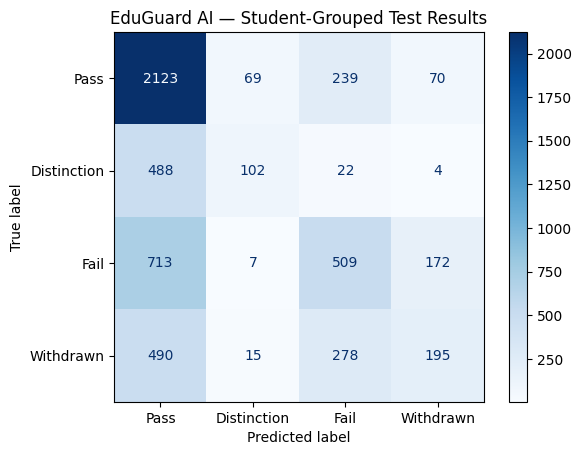

In [78]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model_pipeline.predict(X_test)

print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1-score:    {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

class_labels = ["Pass", "Distinction", "Fail", "Withdrawn"]

cm = confusion_matrix(y_test, y_pred, labels=class_labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
).plot(cmap="Blues", values_format="d")

plt.title("EduGuard AI — Student-Grouped Test Results")
plt.show()

In [79]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Simple baseline: always predicts the most common training class
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)

print("MAJORITY-CLASS BASELINE")
print("------------------------")
print(f"Accuracy:          {accuracy_score(y_test, dummy_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, dummy_pred):.4f}")
print(f"Macro F1-score:    {f1_score(y_test, dummy_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, dummy_pred, zero_division=0))

MAJORITY-CLASS BASELINE
------------------------
Accuracy:          0.4551
Balanced Accuracy: 0.2500
Macro F1-score:    0.1564

Classification Report:
              precision    recall  f1-score   support

 Distinction       0.00      0.00      0.00       616
        Fail       0.00      0.00      0.00      1401
        Pass       0.46      1.00      0.63      2501
   Withdrawn       0.00      0.00      0.00       978

    accuracy                           0.46      5496
   macro avg       0.11      0.25      0.16      5496
weighted avg       0.21      0.46      0.28      5496



In [80]:
from sklearn.model_selection import GroupShuffleSplit

# Student IDs corresponding to the current training rows
train_groups = record_ids.loc[X_train.index, "id_student"]

# Split training data into model-training and validation portions
validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

subtrain_idx, val_idx = next(
    validation_splitter.split(X_train, y_train, groups=train_groups)
)

X_subtrain = X_train.iloc[subtrain_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_subtrain = y_train.iloc[subtrain_idx].copy()
y_val = y_train.iloc[val_idx].copy()

print("Model-training records:", len(X_subtrain))
print("Validation records:", len(X_val))

subtrain_students = set(train_groups.iloc[subtrain_idx])
validation_students = set(train_groups.iloc[val_idx])

print(
    "Student overlap:",
    len(subtrain_students.intersection(validation_students))
)

print("\nValidation class distribution:")
print(y_val.value_counts())

Model-training records: 17620
Validation records: 4399
Student overlap: 0

Validation class distribution:
final_result
Pass           2006
Fail           1114
Withdrawn       814
Distinction     465
Name: count, dtype: int64


In [81]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train using only the model-training portion
model_pipeline.fit(X_subtrain, y_subtrain)

# Predict the validation outcomes
y_val_pred = model_pipeline.predict(X_val)

# Display metrics
print(f"Accuracy:          {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")
print(f"Macro F1-score:    {f1_score(y_val, y_val_pred, average='macro'):.4f}")

print("\nValidation Classification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

Accuracy:          0.5374
Balanced Accuracy: 0.3967
Macro F1-score:    0.4055

Validation Classification Report:
              precision    recall  f1-score   support

 Distinction       0.49      0.14      0.22       465
        Fail       0.51      0.40      0.45      1114
        Pass       0.56      0.84      0.67      2006
   Withdrawn       0.46      0.20      0.28       814

    accuracy                           0.54      4399
   macro avg       0.50      0.40      0.41      4399
weighted avg       0.52      0.54      0.49      4399



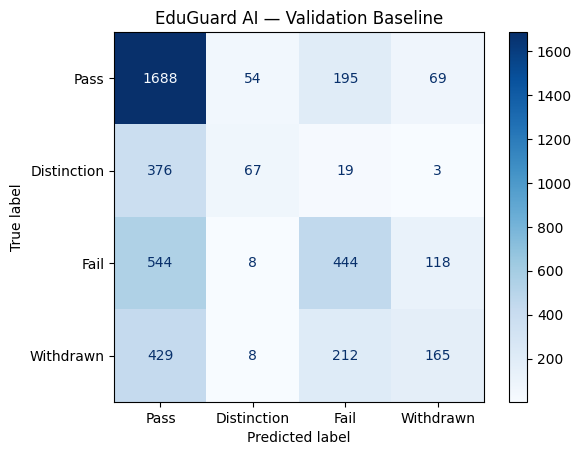

In [82]:
class_labels = ["Pass", "Distinction", "Fail", "Withdrawn"]

cm_val = confusion_matrix(
    y_val,
    y_val_pred,
    labels=class_labels
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_val,
    display_labels=class_labels
).plot(cmap="Blues", values_format="d")

plt.title("EduGuard AI — Validation Baseline")
plt.show()

In [83]:
from sklearn.base import clone

# Copy the existing pipeline without changing the original
rf_subsample = clone(model_pipeline)

# Use balanced class weights for each tree's bootstrap sample
rf_subsample.set_params(
    classifier__class_weight="balanced_subsample"
)

rf_subsample.fit(X_subtrain, y_subtrain)

print("Alternative Random Forest trained successfully.")

Alternative Random Forest trained successfully.


In [84]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

y_val_pred_subsample = rf_subsample.predict(X_val)

print(f"Accuracy:          {accuracy_score(y_val, y_val_pred_subsample):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_pred_subsample):.4f}")
print(f"Macro F1-score:    {f1_score(y_val, y_val_pred_subsample, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_subsample, zero_division=0))

Accuracy:          0.5322
Balanced Accuracy: 0.3919
Macro F1-score:    0.4009

Classification Report:
              precision    recall  f1-score   support

 Distinction       0.49      0.15      0.22       465
        Fail       0.50      0.38      0.43      1114
        Pass       0.55      0.84      0.66      2006
   Withdrawn       0.48      0.20      0.28       814

    accuracy                           0.53      4399
   macro avg       0.50      0.39      0.40      4399
weighted avg       0.52      0.53      0.49      4399



In [85]:
from sklearn.metrics import recall_score
import pandas as pd

comparison = pd.DataFrame(
    {
        "Balanced weights": [
            accuracy_score(y_val, y_val_pred),
            balanced_accuracy_score(y_val, y_val_pred),
            f1_score(y_val, y_val_pred, average="macro"),
            recall_score(y_val, y_val_pred, labels=["Fail"], average=None)[0],
            recall_score(y_val, y_val_pred, labels=["Withdrawn"], average=None)[0]
        ],
        "Balanced subsample": [
            accuracy_score(y_val, y_val_pred_subsample),
            balanced_accuracy_score(y_val, y_val_pred_subsample),
            f1_score(y_val, y_val_pred_subsample, average="macro"),
            recall_score(y_val, y_val_pred_subsample, labels=["Fail"], average=None)[0],
            recall_score(y_val, y_val_pred_subsample, labels=["Withdrawn"], average=None)[0]
        ]
    },
    index=[
        "Accuracy",
        "Balanced accuracy",
        "Macro F1",
        "Fail recall",
        "Withdrawn recall"
    ]
)

comparison.round(4)

,Balanced weights,Balanced subsample
Accuracy,0.5374,0.5322
Balanced accuracy,0.3967,0.3919
Macro F1,0.4055,0.4009
Fail recall,0.3986,0.3770
Withdrawn recall,0.2027,0.2027


In [93]:
from sklearn.inspection import permutation_importance
import pandas as pd

# model_pipeline is the original balanced model,
# fitted on X_subtrain and y_subtrain in the previous step.

perm_result = permutation_importance(
    model_pipeline,
    X_val,
    y_val,
    scoring="f1_macro",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

feature_importance.round(4)

,feature,importance_mean,importance_std
4,early_mean_score,0.0659,0.0011
6,early_min_score,0.0597,0.0012
5,early_max_score,0.0478,0.0027
8,early_active_days,0.0434,0.0037
0,code_module,0.0414,0.0036
7,early_total_clicks,0.0400,0.0020
9,early_unique_sites,0.0290,0.0026
12,highest_education,0.0143,0.0027
3,early_assessment_count,0.0122,0.0017
16,studied_credits,0.0079,0.0020


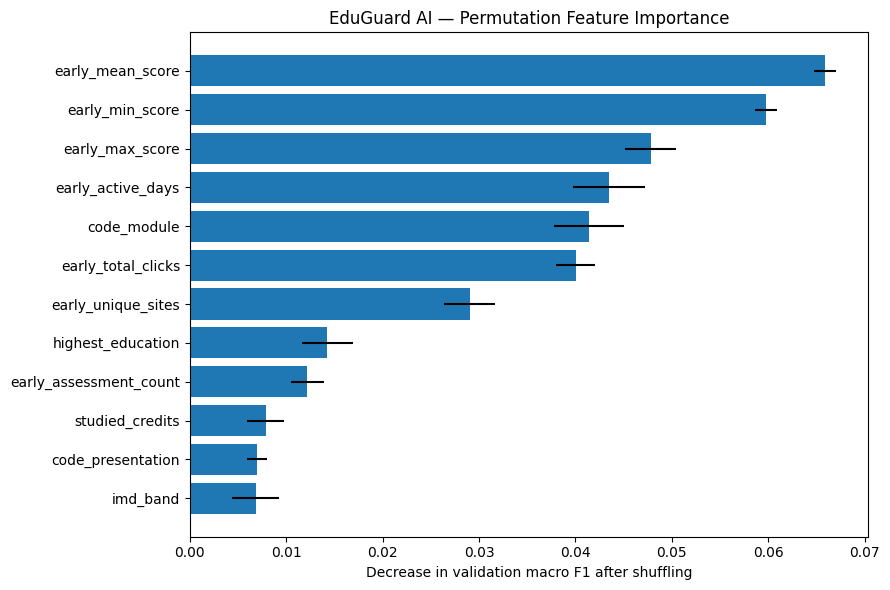

In [91]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(12).sort_values(
    "importance_mean"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["feature"],
    top_features["importance_mean"],
    xerr=top_features["importance_std"]
)
plt.xlabel("Decrease in validation macro F1 after shuffling")
plt.title("EduGuard AI — Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [94]:
print("Pipeline steps:")
for step_name, step_object in model_pipeline.named_steps.items():
    print(f"{step_name}: {type(step_object).__name__}")

Pipeline steps:
preprocessor: ColumnTransformer
classifier: RandomForestClassifier


In [95]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)
import pandas as pd

# Candidate Random Forest settings
experiments = {
    "Current baseline": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1
    },
    "Limited depth": {
        "n_estimators": 200,
        "max_depth": 15,
        "min_samples_leaf": 1
    },
    "Larger leaf": {
        "n_estimators": 200,
        "max_depth": 15,
        "min_samples_leaf": 5
    }
}

results = []

for experiment_name, parameters in experiments.items():

    candidate = clone(model_pipeline)

    candidate.set_params(
        classifier__n_estimators=parameters["n_estimators"],
        classifier__max_depth=parameters["max_depth"],
        classifier__min_samples_leaf=parameters["min_samples_leaf"]
    )

    candidate.fit(X_subtrain, y_subtrain)
    predictions = candidate.predict(X_val)

    results.append({
        "Experiment": experiment_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro"),
        "Fail Recall": recall_score(
            y_val, predictions, labels=["Fail"], average=None
        )[0],
        "Withdrawn Recall": recall_score(
            y_val, predictions, labels=["Withdrawn"], average=None
        )[0],
        "Distinction Recall": recall_score(
            y_val, predictions, labels=["Distinction"], average=None
        )[0]
    })

comparison_results = pd.DataFrame(results).set_index("Experiment")

display(comparison_results.round(4))

,Accuracy,Balanced Accuracy,Macro F1,Fail Recall,Withdrawn Recall,Distinction Recall
Experiment,,,,,,
Current baseline,0.5374,0.3967,0.4055,0.3986,0.2027,0.1441
Limited depth,0.5031,0.4411,0.4440,0.4273,0.3034,0.3785
Larger leaf,0.4767,0.4727,0.4476,0.4354,0.3686,0.5634



Limited depth — Classification Report
              precision    recall  f1-score   support

        Pass       0.57      0.66      0.61      2006
 Distinction       0.35      0.38      0.36       465
        Fail       0.47      0.43      0.45      1114
   Withdrawn       0.42      0.30      0.35       814

    accuracy                           0.50      4399
   macro avg       0.45      0.44      0.44      4399
weighted avg       0.49      0.50      0.50      4399



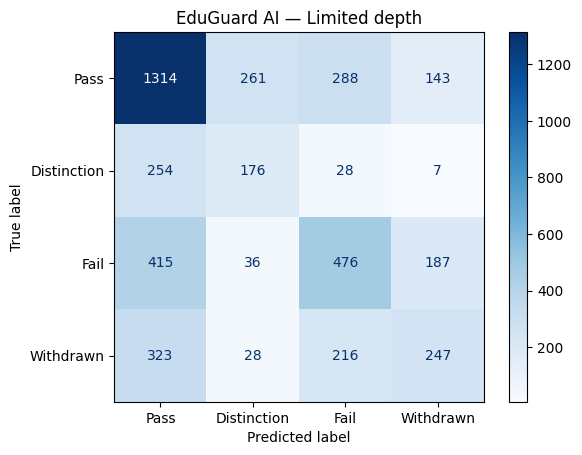


Larger leaf — Classification Report
              precision    recall  f1-score   support

        Pass       0.60      0.52      0.56      2006
 Distinction       0.31      0.56      0.40       465
        Fail       0.46      0.44      0.45      1114
   Withdrawn       0.41      0.37      0.39       814

    accuracy                           0.48      4399
   macro avg       0.44      0.47      0.45      4399
weighted avg       0.50      0.48      0.48      4399



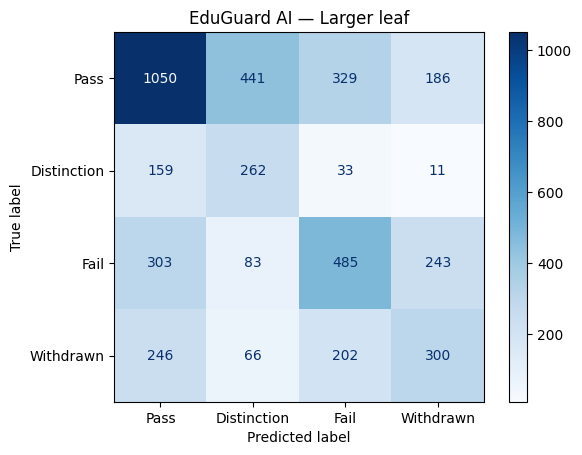

In [96]:
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

candidate_models = {
    "Limited depth": {
        "max_depth": 15,
        "min_samples_leaf": 1
    },
    "Larger leaf": {
        "max_depth": 15,
        "min_samples_leaf": 5
    }
}

class_labels = ["Pass", "Distinction", "Fail", "Withdrawn"]

for name, params in candidate_models.items():

    candidate = clone(model_pipeline)

    candidate.set_params(
        classifier__n_estimators=200,
        classifier__max_depth=params["max_depth"],
        classifier__min_samples_leaf=params["min_samples_leaf"]
    )

    candidate.fit(X_subtrain, y_subtrain)
    predictions = candidate.predict(X_val)

    print(f"\n{name} — Classification Report")
    print(classification_report(
        y_val,
        predictions,
        labels=class_labels,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=class_labels
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"EduGuard AI — {name}")
    plt.show()

In [97]:
from sklearn.base import clone

# Candidate selected using validation results
final_candidate = clone(model_pipeline)

final_candidate.set_params(
    classifier__n_estimators=200,
    classifier__max_depth=15,
    classifier__min_samples_leaf=5,
    classifier__class_weight="balanced"
)

# Train using the full training split
final_candidate.fit(X_train, y_train)

print("Candidate trained on the complete training set.")

Candidate trained on the complete training set.


Accuracy:          0.4740
Balanced Accuracy: 0.4717
Macro F1-score:    0.4468

Final Test Classification Report:
              precision    recall  f1-score   support

 Distinction       0.32      0.57      0.41       616
        Fail       0.46      0.43      0.44      1401
        Pass       0.60      0.51      0.55      2501
   Withdrawn       0.39      0.37      0.38       978

    accuracy                           0.47      5496
   macro avg       0.44      0.47      0.45      5496
weighted avg       0.49      0.47      0.48      5496



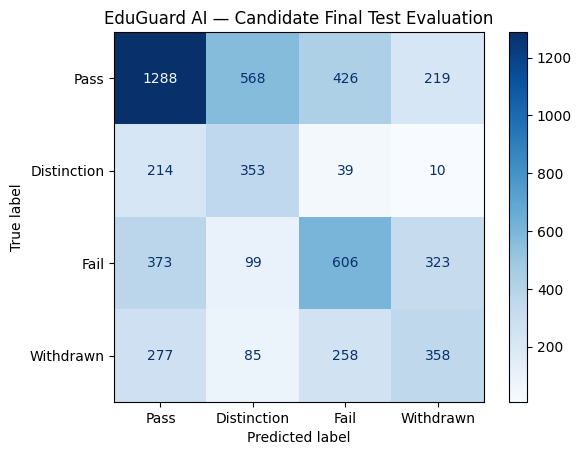

In [98]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_test_pred = final_candidate.predict(X_test)

print(f"Accuracy:          {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_test_pred):.4f}")
print(f"Macro F1-score:    {f1_score(y_test, y_test_pred, average='macro'):.4f}")

print("\nFinal Test Classification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

class_labels = ["Pass", "Distinction", "Fail", "Withdrawn"]

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=class_labels
).plot(cmap="Blues", values_format="d")

plt.title("EduGuard AI — Candidate Final Test Evaluation")
plt.show()

In [99]:
from sklearn.pipeline import Pipeline

for name, obj in globals().copy().items():
    if isinstance(obj, Pipeline):
        print(name, "→", obj)

numeric_transformer → Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])
categorical_transformer → Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])
model_pipeline → Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['date_registration_num',
                                                   'early_assessment_count',
                                                   'early_mean_score',
                                                   'early_max_score',
                                                   'early_min_score',
                                                   'early_total_clicks',
                       

In [100]:
print("Is final_candidate trained?",
      hasattr(final_candidate.named_steps["classifier"], "estimators_"))

print("Is candidate trained?",
      hasattr(candidate.named_steps["classifier"], "estimators_"))

Is final_candidate trained? True
Is candidate trained? True


In [101]:
import joblib
from pathlib import Path

# Create the models folder inside EduGuard_AI
project_root = Path.cwd().parent
models_folder = project_root / "models"
models_folder.mkdir(parents=True, exist_ok=True)

# Save the complete trained pipeline
model_path = models_folder / "eduguard_model.joblib"

joblib.dump(final_candidate, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)
print("File exists:", model_path.exists())

Model saved successfully!
Saved location: C:\Users\User\Desktop\models\eduguard_model.joblib
File exists: True


In [102]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nDoes the EduGuard_AI folder exist here?")
print((Path.cwd() / "EduGuard_AI").exists())

Notebook working directory:
C:\Users\User\Desktop\EduGuard_AI

Does the EduGuard_AI folder exist here?
False


In [103]:
from pathlib import Path
import joblib

# Use the current directory: EduGuard_AI
project_root = Path.cwd()

# Create models folder inside EduGuard_AI
models_folder = project_root / "models"
models_folder.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
model_path = models_folder / "eduguard_model.joblib"
joblib.dump(final_candidate, model_path)

print("Model saved successfully!")
print("Correct location:", model_path)
print("File exists:", model_path.exists())

Model saved successfully!
Correct location: C:\Users\User\Desktop\EduGuard_AI\models\eduguard_model.joblib
File exists: True


In [104]:
import joblib

# Load the saved model from the project folder
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

# Compare predictions from the original and saved models
sample = X_test.iloc[[0]]

original_prediction = final_candidate.predict(sample)
loaded_prediction = loaded_model.predict(sample)

print("Original model prediction:", original_prediction[0])
print("Saved model prediction:   ", loaded_prediction[0])
print("Predictions match:", (original_prediction == loaded_prediction).all())

Model loaded successfully!
Original model prediction: Pass
Saved model prediction:    Pass
Predictions match: True


In [105]:
# Display the exact input columns expected by the trained model
print("Number of input features:", len(X_train.columns))
print("\nExpected input features:")

for i, column in enumerate(X_train.columns, start=1):
    print(f"{i}. {column}")

Number of input features: 18

Expected input features:
1. code_module
2. code_presentation
3. date_registration_num
4. early_assessment_count
5. early_mean_score
6. early_max_score
7. early_min_score
8. early_total_clicks
9. early_active_days
10. early_unique_sites
11. gender
12. region
13. highest_education
14. imd_band
15. age_band
16. num_of_prev_attempts
17. studied_credits
18. disability


In [106]:
%pip install fastapi uvicorn



   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   ---------------------------------------- 2/2 [fastapi]

Note: you may need to restart the kernel to use updated packages.


In [107]:
from pathlib import Path

project_root = Path.cwd()
app_path = project_root / "app.py"

print("Project folder:", project_root)
print("API file path:", app_path)
print("File already exists:", app_path.exists())

Project folder: C:\Users\User\Desktop\EduGuard_AI
API file path: C:\Users\User\Desktop\EduGuard_AI\app.py
File already exists: False


In [1]:
from pathlib import Path

project_root = Path.cwd()

print("Current folder:", project_root)
print("\nFiles and folders found:")

for item in project_root.iterdir():
    print(item.name)

Current folder: C:\Users\User\Desktop\EduGuard_AI

Files and folders found:
.ipynb_checkpoints
01_oulad_dataset_exploration.ipynb
app.py
data
models
notebooks
__pycache__


In [2]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
code = app_path.read_text(encoding="utf-8")

print("App file found:", app_path.exists())
print("Risk calculation present:", "risk_probability = (" in code)
print("Risk returned in response:", '"risk_probability": round(risk_probability, 4)' in code)

App file found: True
Risk calculation present: False
Risk returned in response: False


In [3]:
from pathlib import Path

app_code = r'''
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel


# Load the trained model
PROJECT_DIR = Path(__file__).resolve().parent
MODEL_PATH = PROJECT_DIR / "models" / "eduguard_model.joblib"

model = joblib.load(MODEL_PATH)


# Create the FastAPI application
app = FastAPI(
    title="EduGuard AI API",
    description="Student Performance Prediction and Early Warning System",
    version="1.0.0"
)


# Input schema: 18 features expected by the trained model
class StudentInput(BaseModel):
    code_module: str
    code_presentation: str
    date_registration_num: float
    early_assessment_count: float
    early_mean_score: float
    early_max_score: float
    early_min_score: float
    early_total_clicks: float
    early_active_days: float
    early_unique_sites: float
    gender: str
    region: str
    highest_education: str
    imd_band: str
    age_band: str
    num_of_prev_attempts: float
    studied_credits: float
    disability: str


@app.get("/")
def home():
    return {
        "message": "EduGuard AI API is running",
        "model_loaded": True
    }


@app.post("/predict")
def predict_student_outcome(student: StudentInput):

    # Convert submitted data into a one-row DataFrame
    input_data = pd.DataFrame([student.model_dump()])

    # Predict student outcome and class probabilities
    prediction = model.predict(input_data)[0]
    probabilities = model.predict_proba(input_data)[0]

    # Map each class to its probability
    probability_by_class = {
        str(class_name): float(probability)
        for class_name, probability in zip(model.classes_, probabilities)
    }

    # Combined model-estimated probability of Fail or Withdrawn
    risk_probability = (
        probability_by_class.get("Fail", 0.0)
        + probability_by_class.get("Withdrawn", 0.0)
    )

    return {
        "predicted_outcome": str(prediction),
        "class_probabilities": {
            name: round(probability, 4)
            for name, probability in probability_by_class.items()
        },
        "risk_probability": round(risk_probability, 4),
        "note": (
            "Risk probability is the model-estimated combined probability "
            "of Fail or Withdrawn. It is not a guaranteed outcome."
        )
    }
'''

app_path = Path.cwd() / "app.py"
app_path.write_text(app_code, encoding="utf-8")

# Verify the saved file
saved_code = app_path.read_text(encoding="utf-8")

print("Updated app.py successfully!")
print("File exists:", app_path.exists())
print("Risk calculation present:", "risk_probability = (" in saved_code)
print("Risk returned in response:", '"risk_probability": round(risk_probability, 4)' in saved_code)

Updated app.py successfully!
File exists: True
Risk calculation present: True
Risk returned in response: True


In [7]:
# Find the dataset and target variables currently available in memory

for name in sorted(globals()):
    if any(word in name.lower() for word in ["x_val", "y_val", "validation", "x_test", "y_test"]):
        value = globals()[name]
        print(f"{name}: {type(value).__name__}", end="")

        if hasattr(value, "shape"):
            print(f" | Shape: {value.shape}")
        else:
            print()

In [8]:
print("Variables containing train, val, or test:\n")

for name in sorted(globals()):
    if any(word in name.lower() for word in ["train", "val", "test"]):
        value = globals()[name]

        if hasattr(value, "shape"):
            print(f"{name}: {type(value).__name__}, shape = {value.shape}")
        else:
            print(f"{name}: {type(value).__name__}")

Variables containing train, val, or test:



In [9]:
from pathlib import Path

project_root = Path.cwd()

for folder_name in ["data", "models"]:
    folder = project_root / folder_name
    print(f"\n--- {folder_name.upper()} ---")

    for item in folder.rglob("*"):
        if item.is_file():
            print(item.relative_to(project_root))


--- DATA ---
data\raw\assessments.csv
data\raw\courses.csv
data\raw\OULAD.names
data\raw\studentAssessment.csv
data\raw\studentInfo.csv
data\raw\studentRegistration.csv
data\raw\studentVle.csv
data\raw\vle.csv

--- MODELS ---
models\eduguard_model.joblib


In [10]:
from pathlib import Path
import json

notebook_path = Path.cwd() / "01_oulad_dataset_exploration.ipynb"

if not notebook_path.exists():
    notebook_path = Path.cwd() / "notebooks" / "01_oulad_dataset_exploration.ipynb"

print("Notebook found:", notebook_path.exists())
print("Notebook path:", notebook_path)

notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

print("\n--- Cells mentioning data splitting or validation ---")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell.get("source", []))

        if any(term in code.lower() for term in [
            "train_test_split",
            "group",
            "x_train",
            "x_val",
            "validation",
            "test_size"
        ]):
            print(f"\n--- Cell {i} ---")
            print(code[:2500])

Notebook found: True
Notebook path: C:\Users\User\Desktop\EduGuard_AI\01_oulad_dataset_exploration.ipynb

--- Cells mentioning data splitting or validation ---

--- Cell 34 ---
print("Unique students in student_assessment:")
print(student_assessment["id_student"].nunique())

print("\nUnique assessments:")
print(student_assessment["id_assessment"].nunique())

print("\nRecords per student (summary):")
print(student_assessment.groupby("id_student").size().describe())

--- Cell 52 ---
assessment_features = (
    early_assessments
    .groupby(["id_student", "code_module", "code_presentation"])
    .agg(
        early_assessment_count=("id_assessment", "count"),
        early_mean_score=("score_numeric", "mean"),
        early_max_score=("score_numeric", "max"),
        early_min_score=("score_numeric", "min")
    )
    .reset_index()
)

print("Students with at least one early assessment:", len(assessment_features))
assessment_features.head()

--- Cell 54 ---
import pandas as pd

chunk_size

In [11]:
from pathlib import Path
import json

notebook_path = Path.cwd() / "01_oulad_dataset_exploration.ipynb"

if not notebook_path.exists():
    notebook_path = Path.cwd() / "notebooks" / "01_oulad_dataset_exploration.ipynb"

notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

for i in range(90, min(104, len(notebook["cells"]))):
    cell = notebook["cells"][i]

    if cell["cell_type"] == "code":
        code = "".join(cell.get("source", []))
        if code.strip():
            print(f"\n--- Cell {i} ---")
            print(code)


--- Cell 90 ---
from sklearn.base import clone

# Candidate selected using validation results
final_candidate = clone(model_pipeline)

final_candidate.set_params(
    classifier__n_estimators=200,
    classifier__max_depth=15,
    classifier__min_samples_leaf=5,
    classifier__class_weight="balanced"
)

# Train using the full training split
final_candidate.fit(X_train, y_train)

print("Candidate trained on the complete training set.")

--- Cell 91 ---
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_test_pred = final_candidate.predict(X_test)

print(f"Accuracy:          {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_test_pred):.4f}")
print(f"Macro F1-score:    {f1_score(y_test, y_test_pred, average='macro'):.4f}")

print("\nFinal Test Classification Report:")
print(classi

In [12]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [13]:
from pathlib import Path

frontend_code = r'''
import requests
import streamlit as st

API_URL = "http://127.0.0.1:8000/predict"

st.set_page_config(
    page_title="EduGuard AI",
    page_icon="🎓",
    layout="wide"
)

st.title("🎓 EduGuard AI")
st.subheader("Student Performance Prediction and Early Warning System")
st.write(
    "Enter a student's information and early learning activity "
    "to receive a predicted academic outcome."
)

st.info(
    "This is an experimental model. Its prediction is an estimate, "
    "not a guaranteed student outcome."
)

with st.form("student_prediction_form"):

    st.header("1. Course Information")

    col1, col2 = st.columns(2)

    with col1:
        code_module = st.selectbox(
            "Module",
            ["AAA", "BBB", "CCC", "DDD", "EEE", "FFF", "GGG"]
        )

    with col2:
        code_presentation = st.selectbox(
            "Presentation",
            ["2013J", "2014J", "2013B", "2014B"]
        )

    date_registration_num = st.number_input(
        "Registration date (days relative to course start)",
        value=-30.0,
        step=1.0
    )

    st.header("2. Early Learning Activity")

    col1, col2, col3 = st.columns(3)

    with col1:
        early_assessment_count = st.number_input(
            "Early assessments completed",
            min_value=0,
            value=2,
            step=1
        )

        early_mean_score = st.number_input(
            "Average early assessment score",
            min_value=0.0,
            max_value=100.0,
            value=75.0
        )

        early_max_score = st.number_input(
            "Highest early assessment score",
            min_value=0.0,
            max_value=100.0,
            value=85.0
        )

        early_min_score = st.number_input(
            "Lowest early assessment score",
            min_value=0.0,
            max_value=100.0,
            value=65.0
        )

    with col2:
        early_total_clicks = st.number_input(
            "Total VLE clicks by Day 28",
            min_value=0,
            value=120,
            step=1
        )

        early_active_days = st.number_input(
            "Active learning days",
            min_value=0,
            max_value=28,
            value=15,
            step=1
        )

        early_unique_sites = st.number_input(
            "Unique learning resources accessed",
            min_value=0,
            value=8,
            step=1
        )

    st.header("3. Student Background")

    col1, col2, col3 = st.columns(3)

    with col1:
        gender = st.selectbox("Gender", ["M", "F"])

        region = st.selectbox(
            "Region",
            [
                "East Anglian Region",
                "Scotland",
                "North Western Region",
                "South East Region",
                "West Midlands Region",
                "Wales",
                "North Region",
                "South Region",
                "South West Region",
                "East Midlands Region",
                "Yorkshire Region",
                "London Region",
                "South West England",
                "East Midlands",
                "Other Region"
            ]
        )

        highest_education = st.selectbox(
            "Highest education",
            [
                "A Level or Equivalent",
                "HE Qualification",
                "Lower Than A Level",
                "Post Graduate Qualification",
                "No Formal quals"
            ]
        )

    with col2:
        imd_band = st.selectbox(
            "IMD band",
            [
                "0-10%",
                "10-20%",
                "20-30%",
                "30-40%",
                "40-50%",
                "50-60%",
                "60-70%",
                "70-80%",
                "80-90%",
                "90-100%",
                "Unknown"
            ]
        )

        age_band = st.selectbox(
            "Age band",
            ["0-35", "35-55", "55<="]
        )

        num_of_prev_attempts = st.number_input(
            "Previous attempts",
            min_value=0,
            value=0,
            step=1
        )

    with col3:
        studied_credits = st.number_input(
            "Studied credits",
            min_value=0,
            value=60,
            step=1
        )

        disability = st.selectbox(
            "Declared disability",
            ["N", "Y"]
        )

    submitted = st.form_submit_button(
        "Predict Student Outcome",
        type="primary",
        use_container_width=True
    )

if submitted:

    student_data = {
        "code_module": code_module,
        "code_presentation": code_presentation,
        "date_registration_num": date_registration_num,
        "early_assessment_count": early_assessment_count,
        "early_mean_score": early_mean_score,
        "early_max_score": early_max_score,
        "early_min_score": early_min_score,
        "early_total_clicks": early_total_clicks,
        "early_active_days": early_active_days,
        "early_unique_sites": early_unique_sites,
        "gender": gender,
        "region": region,
        "highest_education": highest_education,
        "imd_band": imd_band,
        "age_band": age_band,
        "num_of_prev_attempts": num_of_prev_attempts,
        "studied_credits": studied_credits,
        "disability": disability
    }

    try:
        with st.spinner("Getting prediction from EduGuard AI..."):
            response = requests.post(
                API_URL,
                json=student_data,
                timeout=30
            )

        if response.status_code == 200:
            result = response.json()

            st.header("Prediction Result")

            outcome = result["predicted_outcome"]
            risk = result["risk_probability"]

            st.metric("Predicted Outcome", outcome)
            st.metric("Estimated Risk of Fail or Withdrawal", f"{risk:.1%}")

            st.subheader("Model-estimated class probabilities")

            probabilities = result["class_probabilities"]

            for class_name, probability in probabilities.items():
                st.write(f"**{class_name}: {probability:.1%}**")
                st.progress(float(probability))

            st.caption(result.get("note", ""))

            st.warning(
                "Use this result as an early-support signal, not as a "
                "final judgment about a student. The model's probabilities "
                "are estimates and may be inaccurate."
            )

        else:
            st.error(
                f"API returned status {response.status_code}: "
                f"{response.text}"
            )

    except requests.exceptions.ConnectionError:
        st.error(
            "Could not connect to the prediction API. "
            "Make sure the FastAPI server is running at "
            "http://127.0.0.1:8000."
        )

    except requests.exceptions.RequestException as error:
        st.error(f"Request failed: {error}")
'''

frontend_path = Path.cwd() / "streamlit_app.py"
frontend_path.write_text(frontend_code, encoding="utf-8")

print("Frontend file created:", frontend_path)
print("File exists:", frontend_path.exists())

Frontend file created: C:\Users\User\Desktop\EduGuard_AI\streamlit_app.py
File exists: True


In [15]:
import requests
import streamlit as st

# API address
API_URL = "http://127.0.0.1:8000/predict"

# Page setup
st.set_page_config(
    page_title="EduGuard AI",
    page_icon="🎓",
    layout="wide"
)

st.title("🎓 EduGuard AI")
st.subheader("Student Performance Prediction and Early Warning System")

st.write(
    "Enter a student's course details and learning activity "
    "to receive an estimated academic outcome."
)

st.info(
    "This is an experimental AI model. Its predictions are estimates, "
    "not guaranteed results or final academic decisions."
)

# --------------------------------------------------
# GLOSSARY
# --------------------------------------------------

with st.expander("📘 What do these terms mean? Click to learn"):

    st.markdown("""
    ### Course Information
    - **Module:** The course or subject the student is studying.
    - **Presentation:** The academic session in which the course is offered.
    - **Registration date:** Number of days between registration and the course start.
      A negative number means the student registered before the course began.

    ### Early Learning Activity
    - **Assessments completed:** Number of assessments submitted by Day 28.
    - **Mean score:** Average mark across the early assessments.
    - **Highest score:** Highest mark received in an early assessment.
    - **Lowest score:** Lowest mark received in an early assessment.
    - **Total clicks:** Number of times the student clicked online learning materials.
    - **Active days:** Number of different days the student accessed learning materials.
    - **Unique sites:** Number of different online learning resources accessed.

    ### Student Background
    - **Gender:** Gender category recorded in the dataset.
    - **Region:** Student's geographical region.
    - **Highest education:** Student's previous education level.
    - **IMD band:** A category describing the deprivation level of the student's area.
    - **Age band:** Student's age group.
    - **Previous attempts:** Number of earlier attempts at the same module.
    - **Studied credits:** Number of academic credits the student is registered to study.
    - **Disability:** Whether the student has declared a disability in the dataset.

    ### Prediction Results
    - **Predicted outcome:** The outcome category selected by the model.
    - **Class probabilities:** The model's estimated probability for each outcome.
    - **Estimated risk:** The model's Fail probability plus its Withdrawn probability.
    - **Day 28:** The model uses information available during the first 28 days.
    """)

# --------------------------------------------------
# INPUT FORM
# --------------------------------------------------

with st.form("student_form"):

    st.header("1. Course Information")

    col1, col2 = st.columns(2)

    with col1:
        code_module = st.selectbox(
            "Module",
            ["AAA", "BBB", "CCC", "DDD", "EEE", "FFF", "GGG"],
            help="Select the course or subject the student is enrolled in."
        )

    with col2:
        code_presentation = st.selectbox(
            "Presentation",
            ["2013J", "2014J", "2013B", "2014B"],
            help="Select the academic session in which the course is offered."
        )

    date_registration_num = st.number_input(
        "Registration date",
        value=-30,
        step=1,
        help="Number of days relative to the course start. Negative means registration before the course began."
    )

    st.divider()
    st.header("2. Early Learning Activity")
    st.caption("Enter information available during the first 28 days of the course.")

    col1, col2 = st.columns(2)

    with col1:
        early_assessment_count = st.number_input(
            "Assessments completed",
            min_value=0,
            value=2,
            step=1,
            help="Number of assessments submitted by Day 28."
        )

        early_mean_score = st.number_input(
            "Average assessment score",
            min_value=0.0,
            max_value=100.0,
            value=75.0,
            help="Average mark across the student's early assessments."
        )

        early_max_score = st.number_input(
            "Highest assessment score",
            min_value=0.0,
            max_value=100.0,
            value=85.0,
            help="Highest mark received in an early assessment."
        )

        early_min_score = st.number_input(
            "Lowest assessment score",
            min_value=0.0,
            max_value=100.0,
            value=65.0,
            help="Lowest mark received in an early assessment."
        )

    with col2:
        early_total_clicks = st.number_input(
            "Total learning-material clicks",
            min_value=0,
            value=120,
            step=1,
            help="Total number of clicks on online learning materials by Day 28."
        )

        early_active_days = st.number_input(
            "Active learning days",
            min_value=0,
            max_value=28,
            value=15,
            step=1,
            help="Number of different days the student accessed learning materials."
        )

        early_unique_sites = st.number_input(
            "Different learning resources accessed",
            min_value=0,
            value=8,
            step=1,
            help="Number of different online learning resources the student accessed."
        )

    st.divider()
    st.header("3. Student Background")

    col1, col2, col3 = st.columns(3)

    with col1:
        gender = st.selectbox(
            "Gender",
            ["F", "M"],
            help="Gender category recorded in the dataset."
        )

        region = st.selectbox(
            "Region",
            [
                "East Anglian Region",
                "East Midlands Region",
                "Ireland",
                "London Region",
                "North Region",
                "North Western Region",
                "Scotland",
                "South East Region",
                "South Region",
                "South West Region",
                "Wales",
                "West Midlands Region",
                "Yorkshire Region"
            ],
            help="Geographical region recorded for the student."
        )

        highest_education = st.selectbox(
            "Highest previous education",
            [
                "A Level or Equivalent",
                "HE Qualification",
                "Lower Than A Level",
                "No Formal quals",
                "Post Graduate Qualification"
            ],
            help="The student's highest recorded education level before this course."
        )

    with col2:
        imd_band = st.selectbox(
            "Area deprivation category (IMD band)",
            [
                "0-10%",
                "10-20%",
                "20-30%",
                "30-40%",
                "40-50%",
                "50-60%",
                "60-70%",
                "70-80%",
                "80-90%",
                "90-100%",
                "?"
            ],
            help="A dataset category representing the deprivation level of the student's area. '?' means unknown."
        )

        age_band = st.selectbox(
            "Age group",
            ["0-35", "35-55", "55<="],
            help="The student's age category in the dataset."
        )

        num_of_prev_attempts = st.number_input(
            "Previous attempts",
            min_value=0,
            value=0,
            step=1,
            help="Number of previous attempts at this module."
        )

    with col3:
        studied_credits = st.number_input(
            "Credits being studied",
            min_value=0,
            value=60,
            step=10,
            help="Total academic credits the student is registered to study."
        )

        disability = st.selectbox(
            "Disability recorded",
            ["N", "Y"],
            help="Whether a disability is recorded in the dataset. N = No, Y = Yes."
        )

    submitted = st.form_submit_button(
        "🔍 Predict Student Outcome",
        use_container_width=True
    )

# --------------------------------------------------
# SEND INPUT TO API AND DISPLAY RESULT
# --------------------------------------------------

if submitted:

    student_data = {
        "code_module": code_module,
        "code_presentation": code_presentation,
        "date_registration_num": date_registration_num,
        "early_assessment_count": early_assessment_count,
        "early_mean_score": early_mean_score,
        "early_max_score": early_max_score,
        "early_min_score": early_min_score,
        "early_total_clicks": early_total_clicks,
        "early_active_days": early_active_days,
        "early_unique_sites": early_unique_sites,
        "gender": gender,
        "region": region,
        "highest_education": highest_education,
        "imd_band": imd_band,
        "age_band": age_band,
        "num_of_prev_attempts": num_of_prev_attempts,
        "studied_credits": studied_credits,
        "disability": disability
    }

    try:
        response = requests.post(
            API_URL,
            json=student_data,
            timeout=30
        )

        response.raise_for_status()
        result = response.json()

        st.divider()
        st.header("📊 Prediction Result")

        col1, col2 = st.columns(2)

        with col1:
            st.metric(
                "Predicted outcome",
                result["predicted_outcome"]
            )

        with col2:
            risk = result["risk_probability"] * 100

            st.metric(
                "Estimated risk of Fail or Withdrawal",
                f"{risk:.1f}%"
            )

        st.subheader("What does this result mean?")

        st.write(
            "The predicted outcome is the category selected by the AI model "
            "based on the information entered."
        )

        st.write(
            "The estimated risk combines the model's probabilities for "
            "Fail and Withdrawn. It is not a guarantee that the student "
            "will fail or withdraw."
        )

        st.subheader("Model-estimated class probabilities")

        probabilities = result["class_probabilities"]

        for outcome, probability in probabilities.items():
            st.write(f"**{outcome}: {probability * 100:.1f}%**")
            st.progress(float(probability))

        st.warning(
            "Use this prediction only as an additional support signal. "
            "It should not replace instructor judgement, student discussion, "
            "or other academic information."
        )

    except requests.exceptions.ConnectionError:
        st.error(
            "Could not connect to the prediction API. "
            "Please check that the API server is running in its Command Prompt."
        )

    except requests.exceptions.RequestException as error:
        st.error(f"Request failed: {error}")

    except (KeyError, ValueError) as error:
        st.error(f"Could not read the prediction result: {error}")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.divider()
st.caption(
    "EduGuard AI | Experimental student performance prediction system "
    "| Predictions are estimates, not guaranteed outcomes."
)

2026-09-27 18:58:54.933 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 18:58:54.934 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 18:58:54.935 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 18:58:54.937 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 18:58:54.937 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 18:58:54.938 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 18:58:54.940 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 18:58:54.941 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator(_form_data=FormData(form_id='student_form'))

In [16]:
from pathlib import Path
import json

# Your EduGuard project folder
PROJECT = Path(r"C:\Users\User\Desktop\EduGuard_AI")

# Files to collect
files_to_collect = [
    PROJECT / "streamlit_app.py",
    PROJECT / "app.py",
    PROJECT / "01_oulad_dataset_exploration.ipynb",
]

output_file = PROJECT / "eduguard_project_report.txt"

report = []

report.append("=" * 80)
report.append("EDUGUARD AI — PROJECT CODE AND NOTEBOOK REPORT")
report.append("=" * 80)

for file_path in files_to_collect:
    report.append("\n\n" + "=" * 80)
    report.append(f"FILE: {file_path}")
    report.append("=" * 80)

    if not file_path.exists():
        report.append("FILE NOT FOUND")
        continue

    if file_path.suffix == ".ipynb":
        with open(file_path, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        for cell_number, cell in enumerate(notebook.get("cells", []), start=1):
            cell_type = cell.get("cell_type", "unknown")
            source = "".join(cell.get("source", []))

            report.append(f"\n--- CELL {cell_number} [{cell_type}] ---")
            report.append(source)

    else:
        report.append(file_path.read_text(encoding="utf-8"))

# Include project folder structure, excluding large datasets
report.append("\n\n" + "=" * 80)
report.append("PROJECT FOLDER STRUCTURE")
report.append("=" * 80)

for path in sorted(PROJECT.rglob("*")):
    if any(part in {"venv", ".venv", "__pycache__", ".git"} for part in path.parts):
        continue

    if path.is_file():
        report.append(str(path.relative_to(PROJECT)))

output_file.write_text("\n".join(report), encoding="utf-8")

print("Report created successfully!")
print("Saved at:", output_file)
print("File size:", round(output_file.stat().st_size / 1024, 2), "KB")

Report created successfully!
Saved at: C:\Users\User\Desktop\EduGuard_AI\eduguard_project_report.txt
File size: 81.02 KB


In [17]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data/raw")

print("Available dataset files:")
for file in DATA_DIR.glob("*.csv"):
    print("-", file.name)

print("\nColumns in each dataset:")
for file in DATA_DIR.glob("*.csv"):
    df = pd.read_csv(file, nrows=5)
    print(f"\n{file.name}")
    print(df.columns.tolist())

Available dataset files:
- assessments.csv
- courses.csv
- studentAssessment.csv
- studentInfo.csv
- studentRegistration.csv
- studentVle.csv
- vle.csv

Columns in each dataset:

assessments.csv
['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']

courses.csv
['code_module', 'code_presentation', 'module_presentation_length']

studentAssessment.csv
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

studentInfo.csv
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

studentRegistration.csv
['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']

studentVle.csv
['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']

vle.csv
['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']


In [18]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data/raw")

assessments = pd.read_csv(DATA_DIR / "assessments.csv")
student_assessment = pd.read_csv(DATA_DIR / "studentAssessment.csv")
student_info = pd.read_csv(DATA_DIR / "studentInfo.csv")

# Combine assessment details with student marks
assessment_data = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="left"
)

print("Total student assessment records:", len(assessment_data))

print("\nAssessment types:")
print(assessment_data["assessment_type"].value_counts(dropna=False))

print("\nAssessment date summary:")
print(assessment_data["date"].describe())

print("\nStudent submission date summary:")
print(assessment_data["date_submitted"].describe())

print("\nMissing marks:", assessment_data["score"].isna().sum())

print("\nFinal outcome distribution:")
print(student_info["final_result"].value_counts())

print("\nSample assessment records:")
display(assessment_data.head(10))

Total student assessment records: 173912

Assessment types:
assessment_type
TMA     98426
CMA     70527
Exam     4959
Name: count, dtype: int64

Assessment date summary:
count     173912
unique        73
top          222
freq        9744
Name: date, dtype: object

Student submission date summary:
count    173912.000000
mean        116.032942
std          71.484148
min         -11.000000
25%          51.000000
50%         116.000000
75%         173.000000
max         608.000000
Name: date_submitted, dtype: float64

Missing marks: 0

Final outcome distribution:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

Sample assessment records:


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78,AAA,2013J,TMA,19,10.0
1,1752,28400,22,0,70,AAA,2013J,TMA,19,10.0
2,1752,31604,17,0,72,AAA,2013J,TMA,19,10.0
3,1752,32885,26,0,69,AAA,2013J,TMA,19,10.0
4,1752,38053,19,0,79,AAA,2013J,TMA,19,10.0
5,1752,45462,20,0,70,AAA,2013J,TMA,19,10.0
6,1752,45642,18,0,72,AAA,2013J,TMA,19,10.0
7,1752,52130,19,0,72,AAA,2013J,TMA,19,10.0
8,1752,53025,9,0,71,AAA,2013J,TMA,19,10.0
9,1752,57506,18,0,68,AAA,2013J,TMA,19,10.0


In [20]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data/raw")
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load files
assessments = pd.read_csv(DATA_DIR / "assessments.csv")
student_assessment = pd.read_csv(DATA_DIR / "studentAssessment.csv")
student_info = pd.read_csv(DATA_DIR / "studentInfo.csv")

# Join marks with assessment details
data = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="inner"
)

# Convert relevant columns to numeric
data["score"] = pd.to_numeric(data["score"], errors="coerce")
data["date"] = pd.to_numeric(data["date"], errors="coerce")
data["is_banked"] = pd.to_numeric(data["is_banked"], errors="coerce")

# Keep assessments scheduled within Day 0–28
data = data[data["date"].between(0, 28)].copy()

# Exclude banked attempts
data = data[data["is_banked"] == 0].copy()

# Remove records without valid marks
data = data.dropna(subset=["score"])

# Calculate early assessment statistics
early_features = (
    data.groupby(["id_student", "code_module", "code_presentation"])
    .agg(
        early_assessment_count=("score", "count"),
        early_mean_score=("score", "mean"),
        early_max_score=("score", "max"),
        early_min_score=("score", "min")
    )
    .reset_index()
)

# Attach final outcomes
simple_dataset = early_features.merge(
    student_info[
        ["id_student", "code_module", "code_presentation", "final_result"]
    ],
    on=["id_student", "code_module", "code_presentation"],
    how="inner"
)

# Save dataset
output_path = OUTPUT_DIR / "eduguard_simple_dataset.csv"
simple_dataset.to_csv(output_path, index=False)

print("Simplified dataset created successfully!")
print("Shape:", simple_dataset.shape)
print("\nOutcome distribution:")
print(simple_dataset["final_result"].value_counts())
print("\nPreview:")
display(simple_dataset.head(10))
print("\nSaved to:", output_path)

Simplified dataset created successfully!
Shape: (20578, 8)

Outcome distribution:
final_result
Pass           9741
Fail           4526
Withdrawn      4060
Distinction    2251
Name: count, dtype: int64

Preview:


,id_student,code_module,code_presentation,early_assessment_count,early_mean_score,early_max_score,early_min_score,final_result
0,6516,AAA,2014J,1,60.0,60.0,60.0,Pass
1,8462,DDD,2013J,1,93.0,93.0,93.0,Withdrawn
2,11391,AAA,2013J,1,78.0,78.0,78.0,Pass
3,23629,BBB,2013B,1,67.0,67.0,67.0,Fail
4,23698,CCC,2014J,1,78.0,78.0,78.0,Pass
5,23798,BBB,2013J,1,90.0,90.0,90.0,Distinction
6,24213,DDD,2014B,1,78.0,78.0,78.0,Pass
7,24734,AAA,2014J,1,41.0,41.0,41.0,Pass
8,25107,BBB,2013B,1,59.0,59.0,59.0,Pass
9,25261,CCC,2014J,1,78.0,78.0,78.0,Withdrawn



Saved to: data\processed\eduguard_simple_dataset.csv


In [21]:
from pathlib import Path
import pandas as pd
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load simplified dataset
DATA_PATH = Path("data/processed/eduguard_simple_dataset.csv")
df = pd.read_csv(DATA_PATH)

# Features and target
feature_columns = [
    "code_module",
    "code_presentation",
    "early_assessment_count",
    "early_mean_score",
    "early_max_score",
    "early_min_score"
]

X = df[feature_columns]
y = df["final_result"]

# Split by student so the same student cannot appear in both sets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["id_student"])
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Preprocessing
categorical_features = ["code_module", "code_presentation"]
numeric_features = [
    "early_assessment_count",
    "early_mean_score",
    "early_max_score",
    "early_min_score"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_features
        )
    ]
)

# Model
simple_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Train
simple_model.fit(X_train, y_train)

# Evaluate
y_pred = simple_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=simple_model.classes_))
print("\nClass order:", simple_model.classes_)

# Save as a separate model
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

model_path = MODEL_DIR / "eduguard_simple_model.joblib"
joblib.dump(simple_model, model_path)

print("\nSimplified model saved to:", model_path)

Test accuracy: 0.3713

Classification report:
              precision    recall  f1-score   support

 Distinction       0.25      0.66      0.36       469
        Fail       0.32      0.30      0.31       917
        Pass       0.56      0.34      0.42      1942
   Withdrawn       0.33      0.36      0.35       811

    accuracy                           0.37      4139
   macro avg       0.37      0.42      0.36      4139
weighted avg       0.43      0.37      0.38      4139


Confusion matrix:
[[311  24 103  31]
 [169 274 231 243]
 [611 360 657 314]
 [147 192 177 295]]

Class order: ['Distinction' 'Fail' 'Pass' 'Withdrawn']

Simplified model saved to: models\eduguard_simple_model.joblib


In [22]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data/raw")
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load OULAD files
assessments = pd.read_csv(DATA_DIR / "assessments.csv")
student_assessment = pd.read_csv(DATA_DIR / "studentAssessment.csv")
student_info = pd.read_csv(DATA_DIR / "studentInfo.csv")
student_vle = pd.read_csv(DATA_DIR / "studentVle.csv")
registration = pd.read_csv(DATA_DIR / "studentRegistration.csv")

KEYS = ["id_student", "code_module", "code_presentation"]

# -----------------------------------
# 1. Early assessment features
# -----------------------------------
assessment_data = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="inner"
)

assessment_data["date"] = pd.to_numeric(
    assessment_data["date"], errors="coerce"
)
assessment_data["score"] = pd.to_numeric(
    assessment_data["score"], errors="coerce"
)
assessment_data["is_banked"] = pd.to_numeric(
    assessment_data["is_banked"], errors="coerce"
)

early_assessments = assessment_data[
    assessment_data["date"].between(0, 28)
    & (assessment_data["is_banked"] == 0)
].dropna(subset=["score"])

early_features = (
    early_assessments.groupby(KEYS)
    .agg(
        early_assessment_count=("score", "count"),
        early_mean_score=("score", "mean"),
        early_max_score=("score", "max"),
        early_min_score=("score", "min")
    )
    .reset_index()
)

# -----------------------------------
# 2. Early VLE activity features
# -----------------------------------
student_vle["date"] = pd.to_numeric(
    student_vle["date"], errors="coerce"
)
student_vle["sum_click"] = pd.to_numeric(
    student_vle["sum_click"], errors="coerce"
)

early_vle = student_vle[
    student_vle["date"].between(0, 28)
].copy()

vle_features = (
    early_vle.groupby(KEYS)
    .agg(
        early_total_clicks=("sum_click", "sum"),
        early_active_days=("date", "nunique"),
        early_unique_sites=("id_site", "nunique")
    )
    .reset_index()
)

# -----------------------------------
# 3. Student and registration details
# -----------------------------------
registration["date_registration"] = pd.to_numeric(
    registration["date_registration"], errors="coerce"
)
registration["date_unregistration"] = pd.to_numeric(
    registration["date_unregistration"], errors="coerce"
)

student_data = student_info.merge(
    registration,
    on=KEYS,
    how="left"
)

# Exclude students who had already withdrawn by Day 28
student_data = student_data[
    student_data["date_unregistration"].isna()
    | (student_data["date_unregistration"] > 28)
].copy()

# -----------------------------------
# 4. Combine features and outcomes
# -----------------------------------
enhanced_dataset = student_data.merge(
    early_features,
    on=KEYS,
    how="left"
).merge(
    vle_features,
    on=KEYS,
    how="left"
)

# Fill activity counts for students with no recorded early activity
count_columns = [
    "early_assessment_count",
    "early_total_clicks",
    "early_active_days",
    "early_unique_sites"
]

enhanced_dataset[count_columns] = (
    enhanced_dataset[count_columns].fillna(0)
)

# Keep only fields needed for modeling
feature_columns = [
    "code_module",
    "code_presentation",
    "date_registration",
    "early_assessment_count",
    "early_mean_score",
    "early_max_score",
    "early_min_score",
    "early_total_clicks",
    "early_active_days",
    "early_unique_sites",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability"
]

enhanced_dataset = enhanced_dataset[
    KEYS + feature_columns + ["final_result"]
].copy()

# Save
output_path = OUTPUT_DIR / "eduguard_enhanced_dataset.csv"
enhanced_dataset.to_csv(output_path, index=False)

print("Enhanced dataset created!")
print("Shape:", enhanced_dataset.shape)

print("\nOutcome distribution:")
print(enhanced_dataset["final_result"].value_counts())

print("\nMissing values:")
print(enhanced_dataset[feature_columns].isna().sum())

print("\nPreview:")
display(enhanced_dataset.head())

print("\nSaved to:", output_path)

Enhanced dataset created!
Shape: (27538, 22)

Outcome distribution:
final_result
Pass           12361
Fail            7044
Withdrawn       5109
Distinction     3024
Name: count, dtype: int64

Missing values:
code_module                  0
code_module                  0
code_presentation            0
code_presentation            0
date_registration            7
early_assessment_count       0
early_mean_score          7359
early_max_score           7359
early_min_score           7359
early_total_clicks           0
early_active_days            0
early_unique_sites           0
gender                       0
region                       0
highest_education            0
imd_band                     0
age_band                     0
num_of_prev_attempts         0
studied_credits              0
disability                   0
dtype: int64

Preview:


,id_student,code_module,code_presentation,code_module,code_presentation,date_registration,early_assessment_count,early_mean_score,early_max_score,early_min_score,...,early_unique_sites,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,11391,AAA,2013J,AAA,2013J,-159.0,1.0,78.0,78.0,78.0,...,24.0,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,28400,AAA,2013J,AAA,2013J,-53.0,1.0,70.0,70.0,70.0,...,25.0,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,31604,AAA,2013J,AAA,2013J,-52.0,1.0,72.0,72.0,72.0,...,22.0,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
3,32885,AAA,2013J,AAA,2013J,-176.0,1.0,69.0,69.0,69.0,...,18.0,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass
4,38053,AAA,2013J,AAA,2013J,-110.0,1.0,79.0,79.0,79.0,...,20.0,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass



Saved to: data\processed\eduguard_enhanced_dataset.csv


In [23]:
from pathlib import Path
import pandas as pd
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Load enhanced dataset
df = pd.read_csv("data/processed/eduguard_enhanced_dataset.csv")

# Remove duplicate course columns if present
df = df.loc[:, ~df.columns.duplicated()].copy()

# Features and target
feature_columns = [
    "code_module",
    "code_presentation",
    "date_registration",
    "early_assessment_count",
    "early_mean_score",
    "early_max_score",
    "early_min_score",
    "early_total_clicks",
    "early_active_days",
    "early_unique_sites",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability"
]

X = df[feature_columns]
y = df["final_result"]
groups = df["id_student"]

# Student-level train/test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Identify feature types
categorical_features = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

numeric_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Preprocessing
preprocessor = ColumnTransformer([
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numeric_features
    )
])

# Enhanced Random Forest model
enhanced_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Train
enhanced_model.fit(X_train, y_train)

# Evaluate
y_pred = enhanced_model.predict(X_test)

enhanced_accuracy = accuracy_score(y_test, y_pred)
enhanced_macro_f1 = f1_score(y_test, y_pred, average="macro")

print("ENHANCED MODEL RESULTS")
print("----------------------")
print("Test accuracy:", round(enhanced_accuracy, 4))
print("Macro F1-score:", round(enhanced_macro_f1, 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=enhanced_model.classes_))
print("\nClass order:", enhanced_model.classes_)

# Save as a separate model
model_path = Path("models/eduguard_enhanced_model.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(enhanced_model, model_path)

print("\nEnhanced model saved to:", model_path)

# Compare with the simplified baseline
print("\nBASELINE COMPARISON")
print("-------------------")
print("Simplified baseline accuracy: 0.3713")
print("Enhanced model accuracy:", round(enhanced_accuracy, 4))
print("Simplified baseline macro F1: 0.36")
print("Enhanced model macro F1:", round(enhanced_macro_f1, 4))

ENHANCED MODEL RESULTS
----------------------
Test accuracy: 0.4625
Macro F1-score: 0.4406

Classification report:
              precision    recall  f1-score   support

 Distinction       0.30      0.60      0.39       610
        Fail       0.45      0.45      0.45      1419
        Pass       0.59      0.49      0.53      2428
   Withdrawn       0.42      0.35      0.38      1119

    accuracy                           0.46      5576
   macro avg       0.44      0.47      0.44      5576
weighted avg       0.49      0.46      0.47      5576


Confusion matrix:
[[ 363   51  181   15]
 [ 119  636  346  318]
 [ 634  401 1190  203]
 [ 112  310  307  390]]

Class order: ['Distinction' 'Fail' 'Pass' 'Withdrawn']

Enhanced model saved to: models\eduguard_enhanced_model.joblib

BASELINE COMPARISON
-------------------
Simplified baseline accuracy: 0.3713
Enhanced model accuracy: 0.4625
Simplified baseline macro F1: 0.36
Enhanced model macro F1: 0.4406


In [24]:

from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

# Load the enhanced model
PROJECT_DIR = Path(__file__).resolve().parent
MODEL_PATH = PROJECT_DIR / "models" / "eduguard_enhanced_model.joblib"

model = joblib.load(MODEL_PATH)

app = FastAPI(
    title="EduGuard AI",
    description="Experimental student performance prediction system",
    version="2.0.0"
)


class StudentInput(BaseModel):
    # Course name is for display only; the model uses OULAD module codes.
    course_name: str = Field(min_length=1)

    code_module: str
    code_presentation: str

    date_registration: float
    early_assessment_count: float = Field(ge=0)
    early_mean_score: float | None = Field(default=None, ge=0, le=100)
    early_max_score: float | None = Field(default=None, ge=0, le=100)
    early_min_score: float | None = Field(default=None, ge=0, le=100)

    early_total_clicks: float = Field(ge=0)
    early_active_days: float = Field(ge=0, le=28)
    early_unique_sites: float = Field(ge=0)

    gender: str
    region: str
    highest_education: str
    imd_band: str
    age_band: str
    num_of_prev_attempts: float = Field(ge=0)
    studied_credits: float = Field(gt=0)
    disability: str


@app.get("/")
def home():
    return {
        "message": "EduGuard AI API is running",
        "model_loaded": True,
        "model_version": "enhanced"
    }


@app.post("/predict")
def predict_student_outcome(student: StudentInput):
    # Build exactly the feature columns used during enhanced-model training.
    input_data = pd.DataFrame([{
        "code_module": student.code_module,
        "code_presentation": student.code_presentation,
        "date_registration": student.date_registration,
        "early_assessment_count": student.early_assessment_count,
        "early_mean_score": student.early_mean_score,
        "early_max_score": student.early_max_score,
        "early_min_score": student.early_min_score,
        "early_total_clicks": student.early_total_clicks,
        "early_active_days": student.early_active_days,
        "early_unique_sites": student.early_unique_sites,
        "gender": student.gender,
        "region": student.region,
        "highest_education": student.highest_education,
        "imd_band": student.imd_band,
        "age_band": student.age_band,
        "num_of_prev_attempts": student.num_of_prev_attempts,
        "studied_credits": student.studied_credits,
        "disability": student.disability
    }])

    prediction = model.predict(input_data)[0]
    probabilities = model.predict_proba(input_data)[0]

    probability_by_class = {
        str(label): float(probability)
        for label, probability in zip(model.classes_, probabilities)
    }

    return {
        "course_name": student.course_name,
        "predicted_outcome": str(prediction),
        "class_probabilities": {
            label: round(probability, 4)
            for label, probability in probability_by_class.items()
        },
        "note": (
            "This is an experimental estimate based on OULAD data. "
            "The typed course name is displayed only; predictions use "
            "the selected OULAD module code and entered features."
        )
    }

NameError: name '__file__' is not defined

In [25]:
import requests
import streamlit as st

API_URL = "http://127.0.0.1:8000/predict"

st.set_page_config(
    page_title="EduGuard AI",
    page_icon="🎓",
    layout="centered"
)

st.title("🎓 EduGuard AI")
st.subheader("Student Performance Prediction & Early Warning System")

st.write(
    "Enter early assessment marks and student details "
    "to receive an experimental academic outcome estimate."
)

st.info(
    "This model was trained using the OULAD dataset. "
    "Predictions are estimates, not guaranteed outcomes or final academic decisions."
)

# ---------------- COURSE DETAILS ----------------

st.header("📚 Course Details")

course_name = st.text_input(
    "Enter course name",
    placeholder="Example: Introduction to Python"
)

col1, col2 = st.columns(2)

with col1:
    code_module = st.selectbox(
        "OULAD module code",
        ["AAA", "BBB", "CCC", "DDD", "EEE", "FFF", "GGG"]
    )

with col2:
    code_presentation = st.selectbox(
        "Academic presentation",
        ["2013J", "2014J", "2013B", "2014B"]
    )

st.caption(
    "The course name is displayed in the result. "
    "The module code is used by the trained model."
)

# ---------------- ASSESSMENT MARKS ----------------

st.header("📝 Early Assessment Marks")

marks_text = st.text_input(
    "Enter marks separated by commas",
    placeholder="Example: 75, 82, 68"
)

st.caption("Enter marks out of 100 from assessments completed by Day 28.")

# ---------------- OPTIONAL DETAILS ----------------

with st.expander("📊 Learning activity details"):
    st.write("Enter activity information if available.")

    early_total_clicks = st.number_input(
        "Total online learning clicks by Day 28",
        min_value=0,
        value=0,
        step=1
    )

    early_active_days = st.number_input(
        "Active learning days (0–28)",
        min_value=0,
        max_value=28,
        value=0,
        step=1
    )

    early_unique_sites = st.number_input(
        "Different learning resources accessed",
        min_value=0,
        value=0,
        step=1
    )

with st.expander("👤 Student background"):
    st.write("These details are part of the dataset used to train the model.")

    gender = st.selectbox("Gender", ["F", "M"])

    region = st.selectbox(
        "Region",
        [
            "East Anglian Region",
            "Scotland",
            "North Western Region",
            "South East Region",
            "West Midlands Region",
            "Wales",
            "North Region",
            "South Region",
            "South West Region",
            "East Midlands Region",
            "Yorkshire Region",
            "East Midlands",
            "London Region",
            "South West England",
            "Other Region"
        ]
    )

    highest_education = st.selectbox(
        "Highest education",
        [
            "A Level or Equivalent",
            "HE Qualification",
            "Lower Than A Level",
            "Post Graduate Qualification",
            "No Formal quals"
        ]
    )

    imd_band = st.selectbox(
        "IMD band",
        [
            "0-10%", "10-20%", "20-30%", "30-40%",
            "40-50%", "50-60%", "60-70%", "70-80%",
            "80-90%", "90-100%", "Unknown"
        ]
    )

    age_band = st.selectbox(
        "Age band",
        ["0-35", "35-55", "55<="]
    )

    num_of_prev_attempts = st.number_input(
        "Previous attempts",
        min_value=0,
        value=0,
        step=1
    )

    studied_credits = st.number_input(
        "Studied credits",
        min_value=0,
        value=60,
        step=1
    )

    disability = st.selectbox(
        "Declared disability",
        ["N", "Y"]
    )

with st.expander("⚙️ Additional course information"):
    date_registration = st.number_input(
        "Registration date relative to course start",
        value=-30.0,
        step=1.0,
        help="A negative number means registration occurred before the course started."
    )

# ---------------- PREDICTION ----------------

if st.button("🔍 Predict Student Outcome", type="primary", use_container_width=True):

    if not course_name.strip():
        st.error("Please enter a course name.")

    elif not marks_text.strip():
        st.error("Please enter at least one assessment mark.")

    else:
        try:
            marks = [
                float(mark.strip())
                for mark in marks_text.split(",")
                if mark.strip()
            ]

            if not marks:
                st.error("Please enter at least one valid mark.")

            elif any(mark < 0 or mark > 100 for mark in marks):
                st.error("Marks must be between 0 and 100.")

            else:
                assessment_count = len(marks)
                mean_score = sum(marks) / assessment_count
                max_score = max(marks)
                min_score = min(marks)

                student_data = {
                    "course_name": course_name.strip(),
                    "code_module": code_module,
                    "code_presentation": code_presentation,
                    "date_registration": date_registration,
                    "early_assessment_count": assessment_count,
                    "early_mean_score": mean_score,
                    "early_max_score": max_score,
                    "early_min_score": min_score,
                    "early_total_clicks": early_total_clicks,
                    "early_active_days": early_active_days,
                    "early_unique_sites": early_unique_sites,
                    "gender": gender,
                    "region": region,
                    "highest_education": highest_education,
                    "imd_band": imd_band,
                    "age_band": age_band,
                    "num_of_prev_attempts": num_of_prev_attempts,
                    "studied_credits": studied_credits,
                    "disability": disability
                }

                with st.spinner("EduGuard AI is analyzing the information..."):
                    response = requests.post(
                        API_URL,
                        json=student_data,
                        timeout=30
                    )

                if response.status_code == 200:
                    result = response.json()

                    st.divider()
                    st.header("📊 Prediction Result")
                    st.write(f"**Course:** {course_name}")

                    st.metric(
                        "Predicted Academic Outcome",
                        result["predicted_outcome"]
                    )

                    if "risk_probability" in result:
                        st.metric(
                            "Estimated Fail or Withdrawal Probability",
                            f'{result["risk_probability"]:.1%}'
                        )

                    st.subheader("Model-estimated outcome probabilities")

                    for outcome, probability in result["class_probabilities"].items():
                        st.write(f"**{outcome}: {probability:.1%}**")
                        st.progress(float(probability))

                    st.warning(
                        "This is an experimental estimate based on the OULAD dataset. "
                        "It may be inaccurate and should only be used as an additional "
                        "support signal—not as a final judgment about a student."
                    )

                else:
                    st.error(
                        f"API error {response.status_code}: {response.text}"
                    )

        except ValueError:
            st.error(
                "Invalid marks. Enter numbers separated by commas, "
                "for example: 75, 82, 68"
            )

        except requests.exceptions.ConnectionError:
            st.error(
                "Could not connect to the API. "
                "Check that the API CMD window is still running."
            )

        except requests.exceptions.RequestException as error:
            st.error(f"Request failed: {error}")

st.divider()
st.caption("EduGuard AI | Experimental student performance prediction system")

2026-09-27 19:32:20.321 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 19:32:20.322 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 19:32:20.323 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 19:32:20.323 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 19:32:20.324 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 19:32:20.325 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 19:32:20.326 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 19:32:20.328 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator(_form_data=FormData(form_id='student_form'))